# Coordination de satellites

### Etudiants :
- Jawher JRIBY 3702809
- Mélanie DELLUC 21104033

## 1 - Introduction

L'objectif de ce projet est d'étudier un problème d'allocation multi-agents de tâches dans lequel des tâches d’observations doivent être allouées à des constellations de satellites en orbite autour de la Terre.

...

## 2 - Préparation : Instances et planification des tâches

In [203]:
from typing import Callable, List, Set, Tuple, Dict
from matplotlib.patches import Rectangle
from collections import defaultdict
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
import subprocess
import random
import pydcop
import shlex
import time
import yaml
import os
import re

### 2.1 - Générateur aléatoire

Dans un premier temps, nous allons implémenter un générateur aléatoire d'instances du problème EOSCSP à partir d'un nombre de satellites, d'utilisateurs exclusifs et de tâches. Pour cela, nous devons établir les structures de données nécessaires à la représentation du problème (EOSCSP, satellites, utilisateurs, requêtes, observations, solutions) et leurs contraintes associées avant de générer des instances de chaque élément. 

Nous avons commencé par créer des instances aléatoires générales, donc sans se préoccuper de l'exclusivité. Puis, nous y avons ajouté les contraintes supplémentaires liées au problème d'exclusivité (section 2.1.5). 

#### 2.1.1 - Structures de données

Pour représenter nos satellites, nos utilisateurs, nos observations, etc, nous avons implémenté diverses structures de données basées sur l'article :

---

##### 1. Problème EOSCSP

Un problème EOSCSP est défini par le tuple :

$$
P = (S, U, R, O)
$$


où :
- **S** : ensemble des satellites  
- **U** : ensemble des utilisateurs  
- **R** : ensemble des requêtes  
- **O** : ensemble des opportunités d’observation associées aux requêtes  

Les observations doivent être planifiées afin de satisfaire les requêtes, en respectant les contraintes temporelles, de capacité et d’exclusivité.

---

##### 2. Satellite

Un **satellite** est défini par le tuple :

$$
s =( t^{start}_s, t^{end}_s, \kappa_s, \tau_s)
$$

**Attributs principaux :**
- `t_start_s ∈ ℝ` : début du plan orbital  
- `t_end_s ∈ ℝ` : fin du plan orbital  
- `κ_s ∈ ℕ⁺` : capacité maximale (nombre d’observations possibles sur l’orbite)  
- `τ_s : O × O → ℝ` : fonction donnant le temps de transition entre deux observations  

Dans le code, cette structure correspond typiquement à une classe `Satellite` contenant des paramètres orbitaux et des contraintes de planification.

---

##### 3. Utilisateur

Un **utilisateur** est défini par :

$$
u = (e_u, p_u)
$$

**Attributs principaux :**
- `e_u` : ensemble (éventuellement vide) de fenêtres d’exclusivité  
  $$
  e_u = \{ (s, (t_{start}, t_{end})) \mid s \in S \}
  $$
- `p_u ∈ ℕ⁺` : priorité de l’utilisateur (plus la valeur est faible, plus la priorité est élevée)

On distingue :
- **U_ex** : utilisateurs possédant des fenêtres exclusives  
- **U_unex** : utilisateurs sans exclusivité  

Hypothèse du modèle :
- Un seul utilisateur sans exclusivité : le **planificateur central** \( u_0 \)
- Les fenêtres d’exclusivité ne se chevauchent pas

---

##### 4. Requête

Une **requête** est définie par :

$$
r = (t^{start}_r, t^{end}_r, \Delta_r, \rho_r, p_r, u_r, \theta_r)
$$

**Attributs principaux :**
- `t_start_r, t_end_r ∈ ℝ` : fenêtre de validité  
- `Δ_r ∈ ℝ` : durée requise  
- `ρ_r ∈ ℝ` : récompense si la requête est satisfaite  
- `p_r` : position à observer (latitude, longitude, altitude)  
- `u_r ∈ U` : utilisateur demandeur  
- `θ_r ⊆ O` : ensemble des opportunités d’observation possibles  

Les opportunités d’observation sont calculées dynamiquement selon :
- la configuration de la constellation
- la position demandée
- l’agilité des satellites

---

##### 5. Observation (opportunité d’observation)

Une **observation** est définie par :

$$
o = (t^{start}_o, t^{end}_o, \Delta_o, r_o, \rho_o, s_o, u_o, p_o)
$$

**Attributs principaux :**
- `t_start_o, t_end_o ∈ ℝ` : fenêtre de validité  
- `Δ_o = Δ_{r_o}` : durée  
- `r_o ∈ R` : requête associée  
- `ρ_o ∈ ℝ` : récompense (héritée de la requête dans ce travail)  
- `s_o ∈ S` : satellite supportant l’observation  
- `u_o ∈ U` : propriétaire (utilisateur de la requête)  
- `p_o ∈ ℕ⁺` : priorité  

La distinction entre récompense de requête et d’observation permet de modéliser des effets réels (météo, angle d’incidence), même si elle n’est pas exploitée ici.

---

##### 6. Solution

Une **solution** à un EOSCSP est un ensemble :

$$
M = \{ (o, t) \mid o \in O,\ t \in [t^{start}_o, t^{end}_o] \}
$$

avec les contraintes suivantes :
- au plus **une observation par requête**
- les utilisateurs exclusifs doivent être planifiés **dans leurs fenêtres exclusives**

**Objectif :**
$$
\max \sum_{(o,t)\in M} \rho_o
$$

Dans le code, cela correspond à une structure de planification (planning, mapping, ou agenda).

---

##### 7. Sous-problèmes EOSCSP

Pour un utilisateur \( u \), on définit le sous-problème :

$$
P[u] = (S, U, R[u], O[u])
$$

avec :
- `R[u] = { r ∈ R | u_r = u }`
- `O[u] = { o ∈ O | u_o = u }`

Plus généralement, on note :
- `P[x]` : restriction du problème à une entité `x` (requête, observation, satellite)
- `P[U' | M]` : sous-problème pour un ensemble d’utilisateurs donné un planning partiel `M`
- `P̄` : problème ne considérant que les observations planifiables **hors exclusivités**

---

##### 8. Union de problèmes

L’union de deux problèmes EOSCSP est définie par :

$$
P \cup P' = (S \cup S',\ U \cup U',\ R \cup R',\ O \cup O')
$$

Cette opération est utile pour la **fusion de sous-problèmes** ou la **coordination multi-agents**.


In [204]:
class EOSCSP :
    def __init__(self, eoscsp_id : int, S : Set['Satellite'], U : Set['User'], R : Set['Request'], O : Set['Observation']):
        self.eoscsp_id = eoscsp_id
        self.S = S
        self.U = U 
        self.R = R
        self.O = O

In [205]:
class Satellite :
    def __init__(self, s_id : int, t_start: float, t_end: float, kappa: int, tau: Callable[['Observation', 'Observation'], float]):
        self.s_id = s_id
        self.t_start = t_start
        self.t_end = t_end
        self.kappa = kappa
        self.tau = tau

In [206]:
class User :
    def __init__(self, u_id : int, e : Set[Tuple['Satellite', float, float]], p : int):
        self.u_id = u_id
        self.e = e
        self.p = p

In [207]:
class Request :
    def __init__(self, r_id : int, t_start : float, t_end : float, duration : float, reward : float, p : Tuple[float, float, float], u : User, thetas : List['Observation']):
        self.r_id = r_id
        self.t_start = t_start
        self.t_end = t_end
        self.duration = duration
        self.reward = reward
        self.p = p
        self.u = u
        self.thetas = thetas

In [208]:
class Observation :
    def __init__(self, o_id : int, t_start : float, t_end : float, duration : float, r : 'Request', reward : float, s : 'Satellite', u : 'User', p : int):
        self.o_id = o_id
        self.t_start = t_start 
        self.t_end = t_end
        self.duration = duration
        self.r = r
        self.reward = reward
        self.s = s
        self.u = u
        self.p = p

In [209]:
class Solution :
    def __init__(self, sol_id : int, M : Dict['Observation', float]):
        self.sol_id = sol_id
        self.M = M 

## 2.1.2 - Contraintes générales sur les données

Dans cette partie, nous avons défini des contraintes **au moment de la génération des instances** afin de garantir la cohérence des données, ainsi que des fonctions utilitaires (ex. `overlap`, `tau`) utilisées pour vérifier certaines contraintes temporelles.

---

##### Fonctions utilitaires

- **`overlap([a_start, a_end], [b_start, b_end])`**
  - Détecte si deux intervalles temporels se chevauchent.
  - Utilisée pour éviter des conflits de fenêtres (exclusivités, observations, etc.).

- **`tau(o1, o2)`**
  - Fonction de transition entre deux observations (ex. temps de repointage).
  - Utilisée pour imposer des contraintes de succession sur un même satellite :
    - Si `o2` est planifiée après `o1` :  
      `start(o2) ≥ end(o1) + tau(o1, o2)`.

---

##### Satellite (`Satellite`)

Contraintes appliquées lors de la génération :

- **Fenêtre orbitale valide**
  - `t_start_s < t_end_s`
- **Capacité minimale**
  - `kappa_s ≥ 1`
- *(optionnel, si vérifié dans le code)* **Transition**
  - `tau_s(o1, o2) ≥ 0` pour toute paire `(o1, o2)`

---

##### Utilisateur (`User`)

Contraintes appliquées lors de la génération :

- **Priorité valide**
  - `p_u ≥ 1`

- *(si exclusivités générées ici)* **Fenêtres d’exclusivité cohérentes**
  - chaque fenêtre : `t_start < t_end`
  - *(si hypothèse du modèle)* absence de chevauchement entre fenêtres exclusives

---

##### Requête (`Request`)

Contraintes appliquées lors de la génération :

- **Fenêtre de validité**
  - `t_start_r < t_end_r`
- **Durée**
  - `Δ_r ≥ 0`
  - *(recommandé pour éviter les requêtes impossibles)* `Δ_r ≤ (t_end_r - t_start_r)`
- **Récompense**
  - `ρ_r > 0`

---

##### Observation (`Observation`) *(si générée explicitement)*

Contraintes appliquées lors de la génération :

- **Fenêtre de validité**
  - `t_start_o < t_end_o`
- **Durée cohérente**
  - `Δ_o = Δ_{r_o}`
  - `Δ_o ≤ (t_end_o - t_start_o)`
- **Cohérence des liens**
  - `r_o` est une requête existante
  - `u_o = u_{r_o}`
  - `s_o` est un satellite existant
- *(si modélisé)* **Transition sur un satellite**
  - si `o2` suit `o1` sur `s` : `start(o2) ≥ end(o1) + tau(o1, o2)`

---

##### Remarque

Ces contraintes sont principalement implémentées sous forme de :
- **rejet et régénération** (boucles avec `max_tries`) lors de la création,
- et/ou **assertions** (validation) pour sécuriser la cohérence des instances produites.



In [210]:
def overlap(a_start, a_end, b_start, b_end, eps=1e-9):
    return (a_start < b_end - eps) and (b_start < a_end - eps)

In [211]:
def constraints_satellites(s):
    errors = []

    if s.t_start >= s.t_end :
        errors.append("Sattelite s : invalid time -> start > end")

    if s.kappa < 1 :
        errors.append("Sattelite s : invalid capacity -> kappa < 1")

    return errors

In [212]:
def constraints_users(u):
    errors = []

    if u.p < 1 :
        errors.append("User u : invalid priority -> p < 1")
    
    return errors

In [213]:
def constraints_requests(r):
    errors = []

    if r.t_start >= r.t_end :
        errors.append("Request r : invalid time -> start > end")

    if r.duration <= 0 :
        errors.append("Request r : invalid duration -> duration <= 0")

    if r.reward < 0 :
        errors.append("Request r : invalid reward -> reward < 0")
                
    return errors

In [214]:
def constraints_observations(o, requests, satellites, ex_by_sat=None, eps=1e-9):
    errors = []

    if o.t_start >= o.t_end :
        errors.append("Observation o : invalid time -> start > end")

    if o.r not in requests:
        errors.append("Observation o : unknown request")

    if o.s not in satellites:
        errors.append("Observation o : unknown satellite")

    if not (o.s.t_start <= o.t_start < o.t_end <= o.s.t_end):
        errors.append("Observation o: outside satellite horizon")
        
    # pas de chevauchement partiel avec une exclusive
    if ex_by_sat is not None:
        for (xs, xe) in ex_by_sat.get(o.s.s_id, []):
            if overlap(xs, xe, o.t_start, o.t_end, eps):
                if not (o.t_start + eps >= xs and o.t_end <= xe + eps):
                    errors.append("Observation: partial overlap with exclusive")
                    break

    return errors

In [215]:
def constraints_exclusifs_users(u, satellites, users_exclusifs):
    errors = []

    for (s, start, end) in getattr(u, "e", []) or []:
        if s not in satellites:
            errors.append("Exclusive: unknown satellite")
        elif not (s.t_start <= start < end <= s.t_end):
            errors.append("Exclusive: outside satellite horizon")

    # un seul user exclusif par satellite
    sats_u = {s.s_id for (s, _, _) in getattr(u, "e", []) or []}
    for ue in users_exclusifs:
        if ue is u:
            continue
        sats_ue = {s.s_id for (s, _, _) in getattr(ue, "e", []) or []}
        if sats_u.intersection(sats_ue):
            errors.append("Only one exclusive user allowed per satellite")

    return errors


In [216]:
def tau(o,p):
    return 1.0

#### 2.1.3 - Construction d'instances des données (hors exclusivité)

### Fonctions de contraintes et de validation

Cette section regroupe les fonctions utilisées pour **vérifier la validité des structures de données** et **garantir le respect des contraintes temporelles et structurelles** du problème EOSCSP.

---

#### Chevauchement temporel

La fonction `overlap` permet de détecter un chevauchement strict entre deux intervalles temporels, en tenant compte d’une tolérance numérique.

Contraintes vérifiées :
- deux intervalles se chevauchent s’ils partagent une portion de temps strictement positive ;
- les contacts aux bornes sont autorisés et ne sont pas considérés comme des chevauchements.

---

#### Contraintes sur les satellites

La fonction `constraints_satellites` vérifie la validité des satellites générés.

Contraintes vérifiées :
- la fenêtre temporelle du satellite est valide (`t_start < t_end`) ;
- la capacité du satellite est strictement positive (`κ ≥ 1`).

---

#### Contraintes sur les utilisateurs

La fonction `constraints_users` vérifie la validité des utilisateurs.

Contraintes vérifiées :
- la priorité de l’utilisateur est un entier strictement positif (`p ≥ 1`).

---

#### Contraintes sur les requêtes

La fonction `constraints_requests` vérifie la validité des requêtes.

Contraintes vérifiées :
- la fenêtre temporelle de la requête est valide (`t_start < t_end`) ;
- la durée demandée est strictement positive ;
- la récompense associée est positive.

---

#### Contraintes sur les observations

La fonction `constraints_observations` garantit la cohérence des observations générées.

Contraintes vérifiées :
- la fenêtre temporelle de l’observation est valide (`t_start < t_end`) ;
- l’observation est associée à une requête existante ;
- l’observation est associée à un satellite existant ;
- l’observation est entièrement incluse dans la fenêtre orbitale du satellite ;
- les contraintes d’exclusivité sont respectées :
  - une observation peut être entièrement incluse dans une fenêtre exclusive,
  - ou entièrement en dehors de toute exclusivité,
  - mais **aucun chevauchement partiel avec une exclusivité n’est autorisé**.

---

#### Contraintes sur les utilisateurs exclusifs

La fonction `constraints_exclusifs_users` vérifie la cohérence des utilisateurs disposant d’exclusivités.

Contraintes vérifiées :
- chaque fenêtre d’exclusivité est associée à un satellite existant ;
- chaque fenêtre d’exclusivité est incluse dans la fenêtre orbitale du satellite ;
- un satellite ne peut être associé qu’à **un seul utilisateur exclusif**.

---

#### Fonction de transition

La fonction de transition `τ` est utilisée pour modéliser le coût ou la faisabilité du passage entre deux observations consécutives.

Dans la version actuelle :
- la fonction retourne une valeur constante ;
- elle ne contraint pas encore l’enchaînement des observations, mais constitue une base pour des extensions futures intégrant des contraintes dynamiques (agilité, repositionnement, énergie).

---


In [217]:
def generate_satellites(nb_satellites, horizon, kappa_min, kappa_max, max_tries=10000):
    S = set()
    
    for i in range(nb_satellites) :
        for j in range(max_tries):
            start = 0
            end = start + horizon
            kappa = random.randint(kappa_min, kappa_max)
            s = Satellite(s_id=i, t_start=start,t_end=end,kappa=kappa,tau=None)
            if constraints_satellites(s) == [] :
                S.add(s)
                break
    return S

In [218]:
def generate_users(nb_users, min_priority=1, max_priority=10, fixed_priority=None, max_tries=10000):
    U = set()

    for i in range(nb_users):
        for j in range(max_tries):
            p = fixed_priority if fixed_priority is not None else random.randint(min_priority, max_priority)
            u = User(u_id=i, e=set(), p=p,)

            if constraints_users(u) == [] :
                U.add(u)
                break
    return U


In [245]:
def generate_requests(users, nb_requests_per_user, horizon, d_min, d_max, r_min, r_max, max_tries=10000):
    R = set()
    r_id_global = 0

    for u in users:
        for r_local in range(nb_requests_per_user):
            for _ in range(max_tries):
                d = random.uniform(d_min, d_max)
                start = random.uniform(0.0, horizon - d)
                end = start + random.uniform(d, horizon - start)
                reward = random.uniform(r_min, r_max)

                # (tu avais du code lat/lon/alt mais p=0 finalement)
                p = 0

                r = Request(
                    r_id=r_id_global,
                    t_start=start,
                    t_end=end,
                    duration=d,
                    reward=reward,
                    p=p,
                    u=u,
                    thetas=[],
                )

                # --- AJOUT: index local de requête pour ce user ---
                r.r_local = r_local

                if constraints_requests(r) == []:
                    R.add(r)
                    r_id_global += 1
                    break

    return R

In [220]:
def interval_inside(a_start, a_end, b_start, b_end, eps=1e-9):
    """[a_start,a_end] ⊆ [b_start,b_end]"""
    return (b_start - eps <= a_start) and (a_end <= b_end + eps)

def overlaps_strict(a_start, a_end, b_start, b_end, eps=1e-9):
    """chevauchement strict (non nul)"""
    return (a_start < b_end - eps) and (b_start < a_end - eps)

def exclusive_windows_on_sat(users_exclusifs, sat):
    """liste (u, xs, xe) pour les exclusives sur ce sat"""
    out = []
    for uex in users_exclusifs:
        for (s, xs, xe) in getattr(uex, "e", []) or []:
            if s == sat:
                out.append((uex, float(xs), float(xe)))
    return out

def in_or_out_exclusive_rule(sat, start, end, users_exclusifs):
    """
    True ssi [start,end] est:
      - totalement hors de toutes les exclusives de sat
      - OU totalement inclus dans UNE exclusive de sat
    """
    ex = exclusive_windows_on_sat(users_exclusifs, sat)
    if not ex:
        return True  # aucune exclusive sur ce satellite

    overlapped = [(u, xs, xe) for (u, xs, xe) in ex if overlaps_strict(start, end, xs, xe)]
    if not overlapped:
        return True  # totalement out

    # Si ça chevauche au moins une exclusive, il faut être totalement inclus dans l'une d'elles
    return any(interval_inside(start, end, xs, xe) for (_, xs, xe) in overlapped)

def inside_own_exclusive(u, sat, start, end):
    """True ssi [start,end] est inclus dans une exclusive de u sur sat"""
    for (s, xs, xe) in getattr(u, "e", []) or []:
        if s == sat and interval_inside(start, end, float(xs), float(xe)):
            return True
    return False


def generate_observations(
    satellites, users, requests,
    opp_per_request, obs_window_min, obs_window_max,
    users_exclusifs=None,
    enforce_exclusive_users_inside=True,
    max_tries=10000
):
    O = set()
    users_by_id = {u.u_id: u for u in users}

    if users_exclusifs is None:
        users_exclusifs = [u for u in users if (getattr(u, "e", None) and len(u.e) > 0)]

    o_id_global = 0

    for r in requests:
        for o_local in range(opp_per_request):
            for _ in range(max_tries):
                s = random.choice(list(satellites))

                # fenêtre d'observation candidate
                d = max(r.duration, random.uniform(obs_window_min, obs_window_max))
                start_min = r.t_start
                start_max = r.t_end - d
                if start_max < start_min:
                    continue

                o_start = random.uniform(start_min, start_max)
                o_end = o_start + d

                # --- CONTRAINTE "IN ou OUT" vis-à-vis des exclusives du satellite ---
                if not in_or_out_exclusive_rule(s, float(o_start), float(o_end), users_exclusifs):
                    continue

                # --- Optionnel mais conseillé : si user exclusif, l'observation doit être dans SES exclusives ---
                if enforce_exclusive_users_inside and (getattr(r.u, "e", None) and len(r.u.e) > 0):
                    if not inside_own_exclusive(r.u, s, float(o_start), float(o_end)):
                        continue

                o = Observation(
                    o_id=o_id_global,
                    r=r,
                    u=r.u,
                    s=s,
                    t_start=o_start,
                    t_end=o_end,
                    duration=r.duration,
                    reward=r.reward,
                    p=users_by_id[r.u.u_id].p,
                )

                o.o_local = o_local
                o.r_local = getattr(r, "r_local", None)

                if constraints_observations(o, requests, satellites) == []:
                    O.add(o)
                    r.thetas.append(o)
                    o_id_global += 1
                    break

    return O

In [221]:
def generate_EOSCSP(i, satellites, users, requests, observations):
    return EOSCSP(eoscsp_id=i, S=satellites, U=users, R=requests, O=observations)

In [222]:
def generate_users_exclusifs(k, satellites, nb_users,
                            min_priority=1, max_priority=10,
                            k_excl_per_user=3,
                            e_dur_min=15, e_dur_max=20,
                            max_tries=10000):
    U = set()

    sats = list(satellites)
    random.shuffle(sats)
    nb_users = min(nb_users, len(sats))

    for i in range(nb_users):
        s = sats[i]                      # satellite fixe
        p = random.randint(min_priority, max_priority)
        res = set()

        for _ in range(k_excl_per_user):
            dur = random.uniform(e_dur_min, e_dur_max)
            dur = min(dur, 0.5 * (s.t_end - s.t_start))

            placed = False
            for _try in range(max_tries):
                start = random.uniform(s.t_start, s.t_end - dur)
                end = start + dur
                if all(end <= st or start >= en for (_, st, en) in res):
                    res.add((s, start, end))
                    placed = True
                    break

            if not placed:
                res = None
                break

        if res is None:
            continue

        u = User(u_id=i + k, e=res, p=p)

        if constraints_users(u) == [] and constraints_exclusifs_users(u, satellites, U) == []:
            U.add(u)

    return U


#### Fonctions d'affichage

Nous venons de concevoir toutes les briques utiles à la création d'instances aléatoire du problème EOSCSP. Maintenant, un élément important pour comprendre si nos instances sont cohérentes avec l'objectif, est de visualiser nos instances. C'est pourquoi, nous avons implémenté ces 3 fonctions :
- **plot_eoscsp_windows(P, plan=None)**
    qui affiche le diagramme de Gantt de l'instance P avec potentiellement     le plan d'attribution final.
- **format_eoscsp(P)**
    qui affiche un récapitulatif de l'instance étudiée, avec les utilisateurs, leurs zones d'exclusivité et sur quel satellite celles-ci s'appliquent, mais également les requêtes attribuées à chaque utilisateurs et toutes les observations possibles.
-  **format_solution(sol)**
    qui, à partir d'une solution trouvée, donc une planification des observations, affiche un récapitulatif de la solution trouvée.

In [223]:
def assign_lanes(intervals):
    intervals = sorted(intervals, key=lambda x: (x["start"], x["end"]))
    lane_ends = []
    for it in intervals:
        placed = False
        for lane, last_end in enumerate(lane_ends):
            if it["start"] >= last_end:
                it["lane"] = lane
                lane_ends[lane] = it["end"]
                placed = True
                break
        if not placed:
            it["lane"] = len(lane_ends)
            lane_ends.append(it["end"])
    return intervals, len(lane_ends)


def plot_eoscsp_windows(
    EOSCSP,
    plan=None,
    title="EOSCSP",
    show_labels=True,
    show_exclusives=True,
    show_plan_labels=True,
):
    satellites = EOSCSP.S
    observations = EOSCSP.O
    users = EOSCSP.U

    # --- Satellite order ---
    sat_ids = []
    for idx, s in enumerate(satellites):
        sid = getattr(s, "s_id", idx)
        sat_ids.append(sid)
    sat_ids_sorted = sorted(sat_ids)

    # --- User ids present ---
    user_ids = sorted({getattr(o.u, "u_id", 0) for o in observations})
    if plan is not None:
        user_ids = sorted(set(user_ids) | {getattr(obs.u, "u_id", 0) for obs, _, _ in plan})
    if users is not None:
        user_ids = sorted({u.u_id for u in users} | set(user_ids))

    # --- Colors ---
    cmap = plt.get_cmap("tab10")
    user_color = {uid: cmap(i % 10) for i, uid in enumerate(user_ids)}

    fig, ax = plt.subplots(figsize=(12, 7))

    # Layout parameters
    row_height = 0.8
    y_gap = 0.35

    # --- Time bounds ---
    all_starts = [o.t_start for o in observations]
    all_ends = [o.t_end for o in observations]

    if show_exclusives and users is not None:
        for u in users:
            for ew in getattr(u, "e_u", []):
                all_starts.append(ew.t_start)
                all_ends.append(ew.t_end)

    if plan is not None:
        for obs, start, end in plan:
            all_starts.append(start)
            all_ends.append(end)

    t_min = min(all_starts) if all_starts else 0.0
    t_max = max(all_ends) if all_ends else 1.0

    # Helpers
    def y_of_sat_id(sid):
        return sat_ids_sorted.index(sid) * (row_height + y_gap)

    def sid_of_sat(s_obj):
        return getattr(s_obj, "s_id", None)

    # -------------------------
    # 1) Draw exclusive windows (background, hatched)
    # -------------------------
    if show_exclusives and users is not None:
        for u in users:
            uid = getattr(u, "u_id", 0)
            for ew in getattr(u, "e", []):
                sid = sid_of_sat(ew[0])
                if sid is None or sid not in sat_ids_sorted:
                    continue

                y = y_of_sat_id(sid)
                x = ew[1]
                w = ew[2] - ew[1]
                if w <= 0:
                    continue

                hatched = Rectangle(
                    (x, y),
                    w,
                    row_height,
                    facecolor=user_color.get(uid, cmap(0)),
                    edgecolor=user_color.get(uid, cmap(0)),
                    linewidth=1.0,
                    alpha=0.18,
                    hatch="///",
                    zorder=0,
                )
                ax.add_patch(hatched)

    # -------------------------
    # 2) Draw observation windows (transparent) - STACKED LANES
    # -------------------------
    obs_by_sat = defaultdict(list)

    for o in observations:
        uid = getattr(o.u, "u_id", 0)
        sid = sid_of_sat(o.s)
        if sid is None or sid not in sat_ids_sorted:
            continue

        start = o.t_start
        end = o.t_end
        if end - start <= 0:
            continue

        oid = getattr(o, "o_id", None)

        uid = getattr(o.u, "u_id", 0)
        r_local = getattr(getattr(o, "r", None), "r_local", None)
        o_local = getattr(o, "o_local", None)
        label = f"o{uid},{r_local},{o_local}"

        obs_by_sat[sid].append({
            "start": start,
            "end": end,
            "uid": uid,
            "label": label,
            "oid": oid,  # <-- keep oid so we can reuse the SAME lane for the plan
        })

    # Band for observation windows (unchanged)
    obs_band_height = 0.30
    obs_band_y0 = (row_height - obs_band_height) / 2
    obs_band_y0 += 0.18

    # Map (sid, oid) -> (lane, n_lanes) to reuse for the plan
    obs_lane = {}

    for sid, intervals in obs_by_sat.items():
        intervals, n_lanes = assign_lanes(intervals)

        lane_h = obs_band_height / max(1, n_lanes)
        rect_h = lane_h * 0.85
        y_base = y_of_sat_id(sid)

        for it in intervals:
            start, end = it["start"], it["end"]
            w = end - start
            uid = it["uid"]

            y0 = (
                y_base
                + obs_band_y0
                + it["lane"] * lane_h
                + (lane_h - rect_h) / 2
            )

            # store lane for THIS observation window
            if it.get("oid", None) is not None:
                obs_lane[(sid, it["oid"])] = (it["lane"], n_lanes)

            rect = Rectangle(
                (start, y0),
                w,
                rect_h,
                facecolor=user_color.get(uid, cmap(0)),
                edgecolor="black",
                linewidth=1,
                alpha=0.25,
                zorder=2,
            )
            ax.add_patch(rect)

            if show_labels:
                ax.text(
                    start + w / 2,
                    y0 + rect_h / 2,
                    it["label"],
                    ha="center",
                    va="center",
                    fontsize=8,
                    alpha=0.9,
                    zorder=3,
                )

    # -------------------------
    # 3) Draw plan INSIDE the SAME lane as its observation window
    # -------------------------
    if plan is not None:
        for obs, start, end in plan:
            uid = getattr(obs.u, "u_id", 0)
            sid = sid_of_sat(obs.s)
            if sid is None or sid not in sat_ids_sorted:
                continue
            if end - start <= 0:
                continue

            oid = getattr(obs, "o_id", None)
            y_base = y_of_sat_id(sid)

            # default fallback: draw in the center of the obs band
            n_lanes = 1
            lane_idx = 0

            if oid is not None and (sid, oid) in obs_lane:
                lane_idx, n_lanes = obs_lane[(sid, oid)]

            lane_h = obs_band_height / max(1, n_lanes)
            rect_h = lane_h * 0.85

            # EXACT same y computation as the window lane
            y0 = (
                y_base
                + obs_band_y0
                + lane_idx * lane_h
                + (lane_h - rect_h) / 2
            )

            exec_rect = Rectangle(
                (start, y0),
                end - start,
                rect_h,
                facecolor=user_color.get(uid, cmap(0)),
                edgecolor="black",
                linewidth=2.0,
                alpha=0.90,
                zorder=7,  # above windows
            )
            ax.add_patch(exec_rect)

            if show_plan_labels:
                uid = getattr(obs.u, "u_id", 0)
                r_local = getattr(getattr(obs, "r", None), "r_local", None)
                o_local = getattr(obs, "o_local", None)
                label = f"o{uid},{r_local},{o_local}"
                ax.text(
                    start + (end - start) / 2,
                    y0 + rect_h / 2,
                    label,
                    ha="center",
                    va="center",
                    fontsize=9,
                    alpha=0.95,
                    zorder=8,
                )

    # --- Y axis labels ---
    y_ticks = []
    y_labels = []
    for sid in sat_ids_sorted:
        y_ticks.append(y_of_sat_id(sid) + row_height / 2)
        y_labels.append(f"S{sid}")
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels)

    # --- X axis ---
    ax.set_xlim(t_min - 0.5, t_max + 0.5)
    ax.set_xlabel("time")
    ax.set_ylabel("satellite")
    ax.set_title(title)

    # --- Fix Y limits ---
    if sat_ids_sorted:
        y0 = y_of_sat_id(sat_ids_sorted[0])
        y_last = y_of_sat_id(sat_ids_sorted[-1])
        ax.set_ylim(y0 - 0.2, y_last + row_height + 0.2)

    # --- Legend ---
    handles = []
    labels = []
    for uid in user_ids:
        patch = Rectangle((0, 0), 1, 1, facecolor=user_color[uid], edgecolor="black", alpha=0.25)
        handles.append(patch)
        labels.append(f"u{uid}")
    ax.legend(handles, labels, loc="upper right")

    ax.grid(True, axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

In [224]:
def format_eoscsp(P, max_items=30) -> str:
    """
    P: instance of EOSCSP
    max_items: limit printed items per section to keep it readable
    """

    def sid(s): return getattr(s, "s_id", "?")
    def uid(u): return getattr(u, "u_id", "?")
    def rid(r): return getattr(r, "r_id", "?")
    def oid(o): return getattr(o, "o_id", "?")

    lines = []
    lines.append(f"EOSCSP instance #{P.eoscsp_id}")
    lines.append(f"|S|={len(P.S)} |U|={len(P.U)} |R|={len(P.R)} |O|={len(P.O)}")
    lines.append("")

    # --- Satellites ---
    lines.append("Satellites:")
    for i, s in enumerate(sorted(P.S, key=lambda x: getattr(x, "s_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.S)-max_items} more)")
            break
        lines.append(
            f"  S{sid(s)}: horizon=[{s.t_start:.2f},{s.t_end:.2f}] kappa={getattr(s,'kappa','?')}"
        )
    lines.append("")

    # --- Users + exclusives ---
    lines.append("Users:")
    for i, u in enumerate(sorted(P.U, key=lambda x: getattr(x, "u_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.U)-max_items} more)")
            break

        e = getattr(u, "e", set())
        lines.append(f"  u{uid(u)}: priority={getattr(u,'p','?')} exclusives={len(e)}")
        # print exclusives
        for j, (s, a, b) in enumerate(sorted(list(e), key=lambda t: (sid(t[0]), t[1]))):
            if j >= 10:
                lines.append("    ...")
                break
            lines.append(f"    - (S{sid(s)}, [{a:.2f},{b:.2f}])")
    lines.append("")

    # --- Requests ---
    lines.append("Requests:")
    for i, r in enumerate(sorted(P.R, key=lambda x: getattr(x, "r_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.R)-max_items} more)")
            break
        u = getattr(r, "u", None)
        lines.append(
            f"  r{rid(r)}: user=u{uid(u) if u else '?'} "
            f"duration={getattr(r,'duration','?')} reward={getattr(r,'reward','?')}"
        )
    lines.append("")

    # --- Observations ---
    lines.append("Observations (windows):")
    obs_sorted = sorted(P.O, key=lambda o: (getattr(o.s, "s_id", 0), o.t_start, oid(o)))
    for i, o in enumerate(obs_sorted):
        if i >= max_items:
            lines.append(f"  ... ({len(P.O)-max_items} more)")
            break
        lines.append(
            f"  o{oid(o)}: u{uid(o.u)} on S{sid(o.s)} "
            f"window=[{o.t_start:.2f},{o.t_end:.2f}] "
            f"dur={o.duration:.2f} reward={o.reward:.2f} "
            f"(r{rid(o.r)})"
        )

    return "\n".join(lines)


In [225]:
def format_solution(sol, title=None) -> str:
    """
    sol: instance of Solution with sol.M: dict[Observation, float]
    """
    def sid(s): return getattr(s, "s_id", "?")
    def uid(u): return getattr(u, "u_id", "?")
    def oid(o): return getattr(o, "o_id", "?")
    def rid(r): return getattr(r, "r_id", "?")

    lines = []
    lines.append(title if title else f"Solution #{sol.sol_id}")
    lines.append(f"Planned observations: {len(sol.M)}")
    lines.append("")

    # Compute total reward
    total_reward = sum(getattr(o, "reward", 0.0) for o in sol.M.keys())
    lines.append(f"Total reward (sum of planned observations): {total_reward:.2f}")
    lines.append("")

    # Sort by satellite then start time
    items = []
    for o, start in sol.M.items():
        end = start + getattr(o, "duration", 0.0)
        items.append((getattr(o.s, "s_id", 0), start, end, o))
    items.sort(key=lambda x: (x[0], x[1]))

    current_sid = None
    for s_id, start, end, o in items:
        if current_sid != s_id:
            current_sid = s_id
            lines.append(f"Satellite S{s_id}:")
        lines.append(
            f"  o{oid(o)} (r{rid(o.r)} u{uid(o.u)}): "
            f"start={start:.2f} end={end:.2f} "
            f"dur={o.duration:.2f} reward={o.reward:.2f}"
        )

    return "\n".join(lines)

#### 2.1.4 - Ajout de l'exclusivité

In [246]:
horizon = 300.0

satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 2, horizon, 5.0, 10.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)

eoscsp_2 = generate_EOSCSP(1, satellites, users, requests, observations)

print(f"Generated: |S|={len(satellites)} |U|={len(users)} |R|={len(requests)} |O|={len(observations)}")

Generated: |S|=3 |U|=3 |R|=6 |O|=15


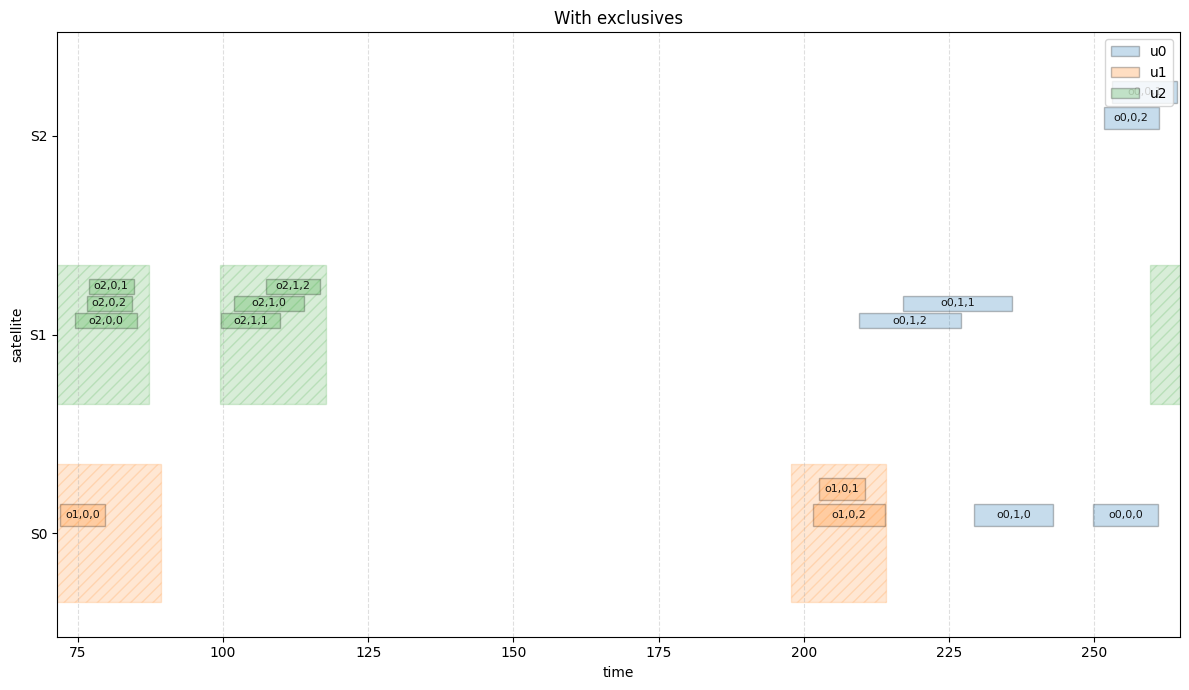

In [247]:
plot_eoscsp_windows(eoscsp_2, title="With exclusives", show_exclusives=True)

### 2.2 - Méthode de planification

Dans un second temps, nous allons concevoir une méthode de planification permettant à un utilisateur de planifier l’exécution d’un ensemble de tâches sur un satellite en tenant compte des contraintes temporelles sur ces tâches.

Dans le but de trouver une solution optimale du plan calculé, mais en limitant tout de même le temps de calcul nécessaire à cette génération, nous comptons implémenter une heuristique gloutonne.

DETAILLER PLUS TARD L'HEURISTIQUE SELON LE CHOIX D'IMPLEMENTATION


RAJOUTER NOTION DE PRIORITE OBSERVATION

#### Contraintes pour la solution

In [248]:
def feasible_window(o, start): # (10)
    return start + o.duration <= o.t_end

In [249]:
def feasible_transition(prev, prev_end, curr, start, tau, eps=1e-9):  # (5)(6)
    return start >= prev_end + tau(prev, curr) - eps

In [250]:
def feasible_no_overlap(o, start, end, plan, eps=1e-9): # non chevauchement réel
    o_sid = getattr(o.s, "s_id", o.s)

    for (obs2, s2, e2) in plan:
        s2_sid = getattr(obs2.s, "s_id", obs2.s)

        # satellites différents => aucun conflit
        if s2_sid != o_sid:
            continue

        # même satellite => pas de chevauchement autorisé
        if overlap(start, end, s2, e2, eps=eps):
            return False

    return True

In [251]:
def feasible_capacity(plan, sat): # (7)
    return len(plan) < sat.kappa

In [252]:
def feasible_one_obs_per_request(o, selected_requests): # (8)
    return o.r not in selected_requests

In [253]:
def feasible_exclusive(o, start, end, users): # exclusives (exécution réelle)
    for u in users:
        for (s,xs,xe) in u.e:
            if s == o.s and overlap(start, end, xs, xe):
                return o.u == u
    return True

### Helpers

In [254]:
def is_exclusive(u):
    return bool(getattr(u, "e", None))

def overlaps_strict(a1, a2, b1, b2):
    return max(a1, b1) < min(a2, b2)

def iter_exclusive_windows_on_sat(u, s):
    for item in getattr(u, "e", []) or []:
        if isinstance(item, tuple) and len(item) == 3:
            sat, xs, xe = item
        elif isinstance(item, tuple) and len(item) == 2 and isinstance(item[1], tuple):
            sat, (xs, xe) = item
        else:
            continue
        if sat == s:
            yield float(xs), float(xe)

def domains_for(o, u):
    if not is_exclusive(u):
        yield (o.s, float(o.t_start), float(o.t_end))
        return

    ok = False
    for xs, xe in iter_exclusive_windows_on_sat(u, o.s):
        a = max(float(o.t_start), xs)
        b = min(float(o.t_end), xe)
        if a <= b:
            ok = True
            yield (o.s, a, b)
    if not ok:
        return

def overlaps_any_exclusive_interval(sat, start, end, U_ex):
    for uex in U_ex:
        for xs, xe in iter_exclusive_windows_on_sat(uex, sat):
            if overlaps_strict(float(start), float(end), float(xs), float(xe)):
                return True
    return False

def plan_reward(plan):
    return sum(float(getattr(o, "reward", getattr(o, "rho", 0.0)) or 0.0) for o, _, _ in plan)

#### Génération d'une solution

In [255]:
def gaps(plan, t_min, t_max):
    if not plan:
        return [(t_min, t_max, None, None)]

    plan = sorted(plan, key=lambda x: x[1])
    res = []

    # before first
    first = plan[0]
    if t_min < first[1]:
        res.append((t_min, first[1], None, first))

    # between
    for i in range(len(plan) - 1):
        prev_item = plan[i]
        next_item = plan[i + 1]
        if prev_item[2] < next_item[1]:
            res.append((prev_item[2], next_item[1], prev_item, next_item))

    # after last
    last = plan[-1]
    if last[2] < t_max:
        res.append((last[2], t_max, last, None))
    return res

In [256]:
def generate_solution(tasks, users=None, lam=0.1, eps=1e-6, tau=tau, sol_id=0, debug=False):
    if not tasks:
        return Solution(sol_id, {}), 0.0, []

    # mono-satellite
    sids = {getattr(t.s, "s_id", id(t.s)) for t in tasks}
    if len(sids) != 1:
        raise ValueError("generate_solution() attend des tasks d'un seul satellite")

    sat = tasks[0].s
    t_min, t_max = sat.t_start, sat.t_end

    def score(o):
        slack = o.t_end - o.t_start
        return (o.reward / o.duration) + lam * (1.0 / max(slack, eps))

    tasks_sorted = sorted(tasks, key=lambda o: (-score(o), o.t_end))

    plan = []
    tot_reward = 0.0
    selected_requests = set()   # (8) one obs per request

    for o in tasks_sorted:
        # (7) capacity kappa
        if not feasible_capacity(plan, sat):
            break

        # (8) one obs per request
        if not feasible_one_obs_per_request(o, selected_requests):
            continue

        best_start = None
        candidate_gaps = gaps(plan, t_min=t_min, t_max=t_max)

        for (g_start, g_end, prev_item, next_item) in candidate_gaps:
            start = max(o.t_start, g_start)
            end = start + o.duration

            # doit tenir dans le gap
            if end > g_end + eps:
                continue

            # transition avec le précédent (si existe)
            if prev_item is not None:
                prev_obs, prev_start, prev_end = prev_item
                if not feasible_transition(prev_obs, prev_end, o, start, tau, eps=eps):
                    continue

            # transition avec le suivant (si existe)
            if next_item is not None:
                next_obs, next_start, next_end = next_item
                if end + tau(o, next_obs) > next_start + eps:
                    continue

            # non-chevauchement (sécurité)
            if not feasible_no_overlap(o, start, end, plan, eps=eps):
                continue

            best_start = start
            break

        if best_start is not None:
            plan.append((o, best_start, best_start + o.duration))
            plan.sort(key=lambda x: x[1])
            tot_reward += o.reward
            selected_requests.add(o.r)

    M = {obs: start for (obs, start, end) in plan}
    return Solution(sol_id=sol_id, M=M), tot_reward, plan


#### Greedy solver pour l'approche enchère
- **first_slot** tente d’insérer une observation dans l’emploi du temps d’un satellite au plus tôt, en tenant compte des fenêtres autorisées et des temps de transition tau. Si l’insertion est valide, elle met à jour R et renvoie l’heure de début.
- **greedy_solver** applique une stratégie gloutonne : on parcourt les observations triées et on insère dès que possible dans la timeline (first_slot). Une fois une requête servie, toutes les alternatives de cette requête sont supprimées.

In [257]:
def first_slot(o, u, R, tau):

    s = o.s
    if len(R[s]) >= s.kappa:
        return None

    for sat, t_start, t_end in domains_for(o, u):

        if len(R[sat]) == 0:
            if float(t_start) + float(o.duration) <= float(t_end):
                R[sat].append((o, float(t_start)))
                return float(t_start)
            continue

        i = 0
        while i <= len(R[sat]):
            t_prime = float(t_start)

            if i > 0:
                o_prev, t_prev = R[sat][i - 1]
                t_prime = max(
                    t_prime,
                    float(t_prev) + float(o_prev.duration) + float(tau(o_prev, o))
                )

            if t_prime + float(o.duration) <= float(t_end):
                if i == len(R[sat]):
                    R[sat].insert(i, (o, t_prime))
                    return t_prime
                else:
                    o_next, t_next = R[sat][i]
                    t_upper = float(t_next) - float(o.duration) - float(tau(o, o_next))
                    if t_prime <= t_upper:
                        R[sat].insert(i, (o, t_prime))
                        return t_prime

            i += 1

    return None

def greedy_solver(P, tau, u=None, restrict_to_exclusives=False, obs_pool=None):

    M_dict = {}
    if obs_pool is None:
        O_sorted = list(P.O)
    else:
        O_sorted = list(obs_pool)

    if u is not None:
        O_sorted = [o for o in O_sorted if o.u == u]

    O_sorted.sort(key=lambda o: (getattr(o, "p", 0), float(o.t_start)))
    R = {s: [] for s in P.S}

    if restrict_to_exclusives:
        if u is None:
            raise ValueError("restrict_to_exclusives=True nécessite de fournir u.")
        u_ctx = u
    else:
        u_ctx = type("NonExclusiveUser", (), {"e": []})()


    i = 0
    while i < len(O_sorted):
        o = O_sorted[i]
        t = first_slot(o, u_ctx, R, tau)
        if t is not None:
            M_dict[o] = float(t)

            r = getattr(o, "r", None)
            if r is not None:
                O_sorted = [oo for oo in O_sorted if getattr(oo, "r", None) != r]
                continue

        i += 1

    plan = [(o, t, t + float(o.duration)) for o, t in M_dict.items()]
    plan.sort(key=lambda x: x[1])
    reward = plan_reward(plan)
    return M_dict, reward, plan

In [258]:
def observations_one_user_one_satellite(observations, u_id, s_id):
    tasks = []
    for o in observations :
        if o.u.u_id == u_id and o.s.s_id == s_id:
            tasks.append(o)
    return tasks

#### Test sur une instance

In [259]:
horizon = 300.0

satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 4, horizon, 5.0, 15.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)

eoscsp_2 = generate_EOSCSP(1, satellites, users, requests, observations)

# user 0
obs_u0 = [o for o in observations if o.u.u_id == 0]
by_sat = {}
for o in obs_u0:
    by_sat.setdefault(o.s.s_id, []).append(o)

best_sid = max(by_sat, key=lambda sid: len(by_sat[sid]))
print(best_sid)
observations_u0_best = by_sat[best_sid]
solution, reward, plan = generate_solution(observations_u0_best, tau=tau)

2


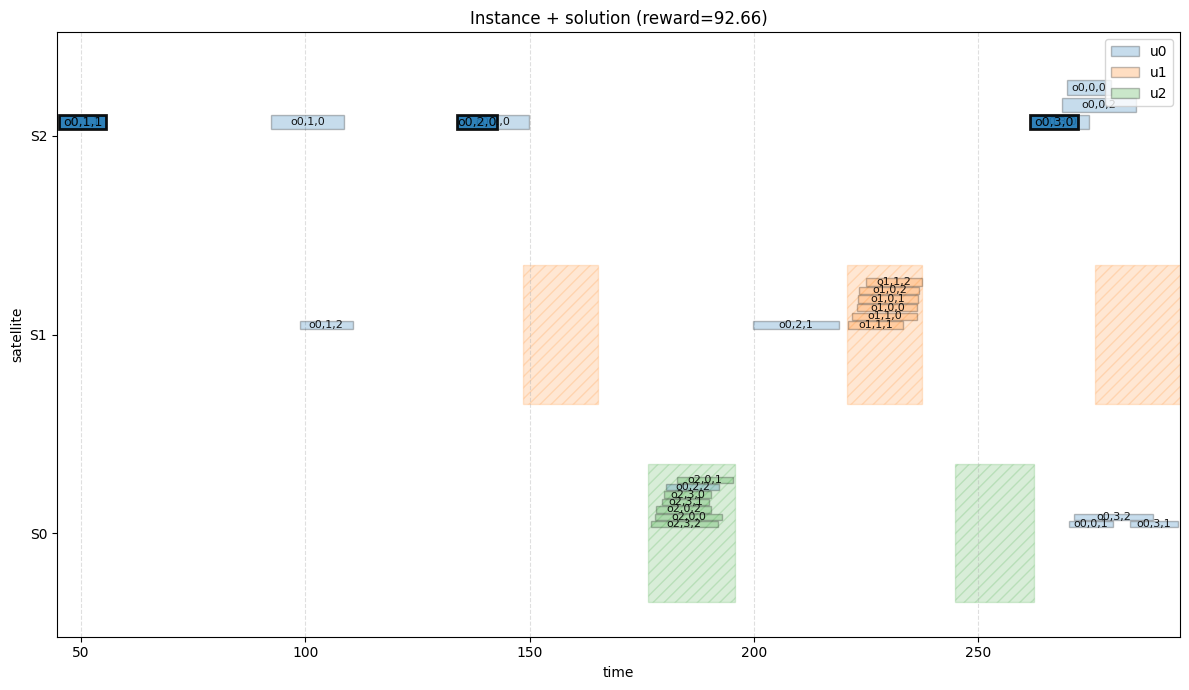

In [260]:
plot_eoscsp_windows(
    eoscsp_2,
    plan=plan,
    title=f"Instance + solution (reward={reward:.2f})",
    show_exclusives=True,
    show_labels=True,  
    show_plan_labels=True
)

In [261]:
# instance
P = generate_EOSCSP(2, satellites, users, requests, observations)
print(format_eoscsp(P, max_items=50))

EOSCSP instance #2
|S|=3 |U|=3 |R|=12 |O|=24

Satellites:
  S0: horizon=[0.00,300.00] kappa=123
  S1: horizon=[0.00,300.00] kappa=107
  S2: horizon=[0.00,300.00] kappa=118

Users:
  u0: priority=9 exclusives=0
  u1: priority=7 exclusives=3
    - (S1, [148.43,165.26])
    - (S1, [220.87,237.53])
    - (S1, [276.20,296.03])
  u2: priority=1 exclusives=3
    - (S0, [24.97,44.44])
    - (S0, [176.39,195.71])
    - (S0, [244.97,262.53])

Requests:
  r0: user=u0 duration=9.810571359946177 reward=6.6737845727166984
  r1: user=u0 duration=10.511141812543851 reward=28.597682840659875
  r2: user=u0 duration=8.8774234887604 reward=43.851224116286815
  r3: user=u0 duration=10.721921405013491 reward=20.211751836069066
  r4: user=u2 duration=12.464436951201957 reward=49.77353762290837
  r5: user=u2 duration=12.113603578631675 reward=34.336756392107674
  r6: user=u2 duration=7.563754310199028 reward=45.76041635725382
  r7: user=u2 duration=10.403688183944894 reward=31.58487799824545
  r8: user=u1 dur

In [262]:
print(format_solution(solution, title="Greedy planning solution"))

Greedy planning solution
Planned observations: 3

Total reward (sum of planned observations): 92.66

Satellite S2:
  o22 (r1 u0): start=45.09 end=55.60 dur=10.51 reward=28.60
  o6 (r2 u0): start=133.90 end=142.78 dur=8.88 reward=43.85
  o3 (r3 u0): start=261.62 end=272.34 dur=10.72 reward=20.21


## 3 - Partie 1 : Optimisation de contraintes distribuées

Dans cette partie, nous allons générer 

#### DCOP Model

Dans un premier temps, nous récupérons l'ensemble des agents exclusifs capables de répondre à la requête r, leurs fenêtres exclusives, et les observations compatibles. (13)

In [153]:
def compute_A_and_Oru(r, theta_r_obs, Uex, eps=1e-9):
    A = []
    Oru = {}
    E_u = {}

    for u in Uex:
        uid = u.u_id
        exclus = list(getattr(u, "e", []) or [])
        E_u[uid] = exclus

        obs_ok = []
        for o in theta_r_obs:
            for (s, xs, xe) in exclus:
                if getattr(s, "s_id", None) != getattr(o.s, "s_id", None):
                    continue
                if overlap(xs, xe, o.t_start, o.t_end, eps=eps):
                    obs_ok.append(o)
                    break

        if obs_ok:
            A.append(u)
            Oru[uid] = obs_ok

    return A, Oru, E_u


Cette fonction nous permet d'évaluer la capacité des satellites, afin de respecter la contrainte de capacité des satellites. (16)

In [154]:
def remaining_capacity_by_satellite(EOSCSP, plans_u):
    used = {}
    for sat in EOSCSP.S:
        sid = sat.s_id
        used[sid] = 0

    for uid, plan in plans_u.items():
        for (o, st, en) in plan:
            sid = o.s.s_id
            used[sid] = used.get(sid, 0) + 1

    kappa_star = {}
    for sat in EOSCSP.S:
        sid = sat.s_id
        kappa_star[sid] = max(0, sat.kappa - used.get(sid, 0))

    return kappa_star


Celle-ci nous rend la fonction objectif afin de maximiser la solution. **pi_cost** permet d’évaluer l’impact négatif potentiel d’une observation sur un plan existant, en termes de perte de récompense.

In [155]:
def pi_cost(o, plan_u, users, lam=0.1, tau=None):
    # On ne garde que les tâches du même satellite que o
    sid_o = getattr(o.s, "s_id", id(o.s))
    tasks_same_sat = [obs for (obs, st, en) in plan_u
                      if getattr(obs.s, "s_id", id(obs.s)) == sid_o]

    # reward avant, sur ce satellite uniquement
    plan_u_same_sat = [(obs, st, en) for (obs, st, en) in plan_u
                       if getattr(obs.s, "s_id", id(obs.s)) == sid_o]
    rew1 = plan_reward(plan_u_same_sat)

    # reward après ajout de o, en réoptimisant seulement ce satellite
    sol2, rew2, plan2 = generate_solution(tasks_same_sat + [o], users=users, lam=lam, tau=tau)

    # coût positif si on perd du reward ; 0 si on gagne
    return max(0.0, rew1 - rew2)

Ce bout de code a pour but de vérifier es contraintes suivantes :
- l’exclusivité concerne le même satellite que l’observation ;
- l’observation et l’exclusivité possèdent une intersection temporelle non vide ;
- la durée de l’observation est compatible avec cette intersection.

In [156]:
# def intersect(a_start, a_end, b_start, b_end):
#     return max(a_start, b_start), min(a_end, b_end)

# def feasible_start_in_exclusive(o, e, eps=1e-9):
#     s, xs, xe = e
#     if s.s_id != o.s.s_id:
#         return None
#     a, b = intersect(xs, xe, o.t_start, o.t_end)
#     start = a
#     if start + o.duration <= b + eps:
#         return start
#     return None

### Résumé des fonctions DCOP / résolution EOSCSP

Cette section résume les fonctions utilisées pour **(i) construire un DCOP local par requête**, **(ii) appeler un solveur pyDCOP**, puis **(iii) appliquer les décisions au planning** afin de produire un plan global.

---

## `build_dcop_request_faithful(...)`

Cette fonction construit un **DCOP centré sur une requête `r`**, puis l’exporte en **YAML**.

Ce que fait la fonction :
- identifie les **agents concernés** `A` (utilisateurs exclusifs), leurs **fenêtres d’exclusivité** `E_u` et leurs **observations candidates** `Oru` pour la requête ;
- calcule la **capacité restante par satellite** (`kappa_star`) à partir des plans déjà construits (`plans_u`) ;
- crée des **variables binaires** \(x\) uniquement si l’affectation est **réellement faisable** (l’observation tient entièrement dans une exclusivité) ;
- associe à chaque variable un **coût souple** :
  - coût = `pi_cost(o, plan_u)` si \(x=1\), sinon 0 ;
  - ce coût représente la **perte potentielle de récompense** induite par l’ajout de l’observation au plan courant (ré-optimisation locale).
- ajoute des **contraintes dures** via une grande pénalité `BIG` :
  - **au plus une** observation sélectionnée pour la requête (`one_obs_for_request`) ;
  - respect de la **capacité restante** de chaque satellite (`cap_s{sid}`) ;
  - **au plus un agent** affecté à une même opportunité d’observation (`one_agent_for_o{oid}`).
- écrit un fichier YAML contenant : domaines, variables, contraintes, agents, objectif `"min"`.

Sorties :
- le chemin du YAML généré ;
- `var_info`, qui mappe chaque variable vers `(uid, obs, satid, start, end)` afin de reconstruire un planning réel après résolution.

---

## `solve_dcop(yaml_path, algo, ...)`

Cette fonction lance **pyDCOP en ligne de commande** pour résoudre le DCOP décrit dans `yaml_path`.

Ce que fait la fonction :
- construit la commande :
  - `pydcop solve --algo <algo> [--timeout ...] [--algo_params ...] <yaml_path>`
- exécute le solveur via `subprocess.run` ;
- renvoie :
  - le code retour (`returncode`),
  - la sortie standard (`stdout`),
  - la sortie erreur (`stderr`).

---

## `parse_assignment_from_stdout(stdout)`

Cette fonction extrait l’affectation (solution) à partir de la sortie texte du solveur.

Ce que fait la fonction :
- détecte des lignes de type `variable = 0/1` (ou `:` / `->`) via une expression régulière ;
- reconstruit un dictionnaire :
  - `assignment[var] = 0 ou 1`.

---

## `apply_dcop_decision(assignment, var_info, plans_u)`

Cette fonction applique la décision DCOP au planning.

Ce que fait la fonction :
- sélectionne les variables choisies (valeur 1) ;
- retrouve leur signification via `var_info` :
  - utilisateur `uid`, observation `obs`, satellite `sid`, intervalle `(st, en)` ;
- ajoute `(obs, st, en)` au plan `plans_u[uid]` ;
- trie le plan de l’utilisateur par date de début.

---

## `s_dcop_EOSCSP_solver(P, tau, algo="dsa")`

Cette fonction orchestre l’ensemble pour produire un plan global EOSCSP.

### Étape 1 — plans initiaux des utilisateurs exclusifs
- pour chaque utilisateur exclusif, planifie **satellite par satellite** uniquement sur ses observations ;
- construit `plans_u[uid]` avec `generate_solution(...)`.

### Étape 2 — boucle de résolution DCOP par requête
- parcourt les requêtes par ordre de date de fin (`t_end`) ;
- pour chaque requête :
  - récupère ses observations candidates `theta_r` ;
  - construit le DCOP YAML via `build_dcop_request_faithful(...)` ;
  - résout via `solve_dcop(...)` avec un algorithme (ex: DSA) ;
  - parse l’affectation (`parse_assignment_from_stdout`) ;
  - applique la décision au plan (`apply_dcop_decision`).

### Étape 3 — planification des utilisateurs non exclusifs
- identifie les observations déjà “prises” par les exclusifs (`observations_to_sup`) ;
- pour chaque utilisateur non exclusif :
  - planifie ses observations restantes,
  - en regroupant par satellite et en appelant `generate_solution(...)` pour chaque satellite.

### Sorties
- `plans_u` : dictionnaire `{uid: plan trié}` ;
- `global_plan` : concaténation des plans utilisateurs (plan global).

---


In [157]:
BIG = 10**6

def build_dcop_request_faithful(
    EOSCSP,
    r,
    theta_r_obs,
    Uex,
    plans_u,
    users_all,
    lam=0.1,
    tau=None,
    out_yaml_path="req.yaml",
    eps=1e-9
):
    A, Oru, E_u = compute_A_and_Oru(r, theta_r_obs, Uex, eps=eps)
    kappa_star = remaining_capacity_by_satellite(EOSCSP, plans_u)

    domains = {"bin": {"values": [0, 1]}}
    variables = {}
    constraints = {}
    agents = [f"u{u.u_id}" for u in A]

    # index pour contrainte "at most one obs for request"
    all_vars = []

    # (X) Construire variables x_{e,o} qui sont réellement faisables
    # et stocker les infos nécessaires (sat, start, end, obs)
    var_info = {}  # var -> (uid, obs, satid)
    for u in A:
        uid = u.u_id
        for o in Oru[uid]:

#                 st = feasible_start_in_exclusive(o, e, eps=eps)
#                 if st is None:
#                     continue
            st = o.t_start
            var = f"x_u{uid}_s{o.s.s_id}_o{o.o_id}"
            variables[var] = {"domain": "bin"}
            all_vars.append(var)
            var_info[var] = (uid, o, o.s.s_id, st, st + o.duration)

            # (18) soft cost: c(x)=pi(o, M_u) if x=1 else 0
            cost = pi_cost(o, plans_u.get(uid, []), users_all, lam=lam, tau=tau)
            constraints[f"cost_{var}"] = {
                "type": "intention",
                "function": f"{cost} if {var} == 1 else 0"
            }

    # (15) au plus UNE variable x_{e,o} == 1 (pour cette requête)
    if all_vars:
        cnt = " + ".join(all_vars)
        constraints["one_obs_for_request"] = {
            "type": "intention",
            "function": f"{BIG} if ({cnt}) > 1 else 0"
        }

    # (16) capacité satellite restante
    # Somme des x liés à un satellite s <= kappa_star[s]
    # (NB: fidèle au passage, mais en vrai, ici on ajoute au plus 1 obs, donc c'est souvent triviale)
    for sat in EOSCSP.S:
        sid = sat.s_id
        cap = kappa_star.get(sid, sat.kappa)
        vars_on_sat = [v for v,info in var_info.items() if info[2] == sid]
        if vars_on_sat:
            cnt = " + ".join(vars_on_sat)
            constraints[f"cap_s{sid}"] = {
                "type": "intention",
                "function": f"{BIG} if ({cnt}) > {cap} else 0"
            }

    # (17) au plus un agent sert la même observation o
    # Somme des x_{*,o} <= 1 pour chaque o
    obs_to_vars = {}
    for v, (uid, o, sid, st, en) in var_info.items():
        obs_to_vars.setdefault(o.o_id, []).append(v)

    for oid, vars_for_o in obs_to_vars.items():
        if len(vars_for_o) > 1:
            cnt = " + ".join(vars_for_o)
            constraints[f"one_agent_for_o{oid}"] = {
                "type": "intention",
                "function": f"{BIG} if ({cnt}) > 1 else 0"
            }

    dcop = {
        "name": f"s_dcop_req_{r.r_id}",
        "objective": "min",
        "domains": domains,
        "variables": variables,
        "constraints": constraints,
        "agents": agents
    }

    out_yaml_path = str(Path(out_yaml_path))
    with open(out_yaml_path, "w", encoding="utf-8") as f:
        yaml.safe_dump(dcop, f, sort_keys=False, allow_unicode=True)

    return out_yaml_path, var_info


In [158]:
def solve_dcop(
    yaml_path,
    algo,
    timeout_s = None,
    algo_params = None,
    extra_args = None,
    cwd = None,
):

    yaml_path = str(Path(yaml_path))

    cmd = ["pydcop", "solve", "--algo", algo]

    if timeout_s is not None:
        cmd += ["--timeout", str(timeout_s)]

    if algo_params:
        # format CLI pyDCOP: --algo_params key:value,key2:value2
        ap = ",".join(f"{k}:{v}" for k, v in algo_params.items())
        cmd += ["--algo_params", ap]

    if extra_args:
        cmd += extra_args

    cmd.append(yaml_path)

    proc = subprocess.run(
        cmd,
        capture_output=True,
        text=True,
        cwd=cwd
    )
    return proc.returncode, proc.stdout, proc.stderr


In [159]:
def apply_dcop_decision(assignment, var_info, plans_u):
    chosen = [v for v,val in assignment.items() if str(val) in ("1", "1.0", "True")]
    for v in chosen:
        if v not in var_info:
            continue
        uid, obs, sid, st, en = var_info[v]

        # éviter doublons
        already = any(obs2.o_id == obs.o_id for (obs2, _, _) in plans_u.get(uid, []))
        if already:
            continue

        plans_u.setdefault(uid, []).append((obs, st, en))
        plans_u[uid].sort(key=lambda x: x[1])

In [160]:
def parse_assignment_from_stdout(stdout):
    assignment = {}

    # regex: variable = value  ou  variable: value
    pattern = re.compile(
        r"(x_[A-Za-z0-9_\.]+)\s*(?:=|:|->)\s*([01])"
    )

    for line in stdout.splitlines():
        line = line.strip()
        m = pattern.search(line)
        if m:
            var = m.group(1)
            val = int(m.group(2))
            assignment[var] = val

    return assignment

In [161]:
def s_dcop_EOSCSP_solver(P, tau, algo="dsa"):
    plans_u = {}
    observations_to_sup = set()
    served_rids = set()  # GLOBAL: une seule observation par requête (via r_id)

    # --- Étape 1 : plans initiaux des users exclusifs (par satellite unique, sans doublons)
    for u in P.U:
        if not getattr(u, "e", None):
            continue

        uid = u.u_id
        plans_u[uid] = []

        # satellites uniques (évite de recalculer le même plan plusieurs fois)
        sat_ids = {s.s_id for (s, xs, xe) in (u.e or [])}
        for sid in sat_ids:
            obs_u_s = observations_one_user_one_satellite(P.O, uid, sid)
            if not obs_u_s:
                continue

            # (optionnel mais conseillé) filtrer déjà les requêtes servies
            obs_u_s = [o for o in obs_u_s if o.r.r_id not in served_rids]
            if not obs_u_s:
                continue

            _, _, plan = generate_solution(obs_u_s, users=P.U, tau=tau)

            # ajouter en respectant 1 obs / requête (global)
            for (obs, st, en) in plan:
                rid = obs.r.r_id
                if rid in served_rids:
                    continue
                plans_u[uid].append((obs, st, en))
                served_rids.add(rid)

        plans_u[uid].sort(key=lambda x: x[1])

    # --- Étape 2 : boucle DCOP sur les requêtes
    for r in sorted(P.R, key=lambda r: r.t_end):
        # si déjà servie globalement, inutile de lancer un DCOP
        if r.r_id in served_rids:
            continue

        theta_r = [o for o in P.O if o.r == r]
        if not theta_r:
            continue

        yaml_path, var_info = build_dcop_request_faithful(
            EOSCSP=P,
            r=r,
            theta_r_obs=theta_r,
            Uex=[u for u in P.U if getattr(u, "e", None)],
            plans_u=plans_u,
            users_all=P.U,
            tau=tau,
        )

        rc, out, err = solve_dcop(yaml_path, algo=algo)
        if rc != 0:
            continue

        assignment = parse_assignment_from_stdout(out)

        # IMPORTANT: appliquer en respectant served_rids (global)
        chosen = [v for v, val in assignment.items() if str(val) in ("1", "1.0", "True")]
        for v in chosen:
            if v not in var_info:
                continue
            uid, obs, sid, st, en = var_info[v]
            rid = obs.r.r_id
            if rid in served_rids:
                continue

            plans_u.setdefault(uid, [])
            # éviter doublon exact d'observation
            if any(obs2.o_id == obs.o_id for (obs2, _, _) in plans_u[uid]):
                continue

            plans_u[uid].append((obs, st, en))
            plans_u[uid].sort(key=lambda x: x[1])
            served_rids.add(rid)

    # --- Marquer les observations déjà prises (pour éviter de les replanifier)
    for plan in plans_u.values():
        for (o, start, end) in plan:
            observations_to_sup.add(o)
            served_rids.add(o.r.r_id)  # sécurité

    # --- Étape 3 : planification "classique" des observations restantes (TOUS users)
    # (y compris exclusifs, afin qu'ils puissent être servis sur d'autres satellites)
    for u in P.U:
        uid = u.u_id
        plans_u.setdefault(uid, [])

        obs_u = [
            o for o in P.O
            if o.u.u_id == uid
            and o not in observations_to_sup
            and o.r.r_id not in served_rids
        ]
        if not obs_u:
            continue

        # regrouper les observations par satellite
        obs_by_sat = {}
        for o in obs_u:
            obs_by_sat.setdefault(o.s.s_id, []).append(o)

        # planifier satellite par satellite
        for sid, obs_u_s in obs_by_sat.items():
            # filtrer AVANT : éviter de planifier des requêtes déjà servies
            obs_u_s = [o for o in obs_u_s if o.r.r_id not in served_rids]
            if not obs_u_s:
                continue

            _, _, plan = generate_solution(obs_u_s, users=P.U, tau=tau)

            # ajouter en respectant 1 obs / requête (global)
            for (obs, st, en) in plan:
                rid = obs.r.r_id
                if rid in served_rids:
                    continue
                # éviter doublon d'observation
                if any(obs2.o_id == obs.o_id for (obs2, _, _) in plans_u[uid]):
                    continue

                plans_u[uid].append((obs, st, en))
                served_rids.add(rid)
                observations_to_sup.add(obs)

        plans_u[uid].sort(key=lambda x: x[1])

    # --- Étape 4 : plan global concaténé
    global_plan = []
    for plan in plans_u.values():
        global_plan.extend(plan)

    return plans_u, global_plan


#### Tests

In [162]:
horizon = 300.0

satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 2, horizon, 5.0, 15.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)

P = generate_EOSCSP(1, satellites, users, requests, observations)

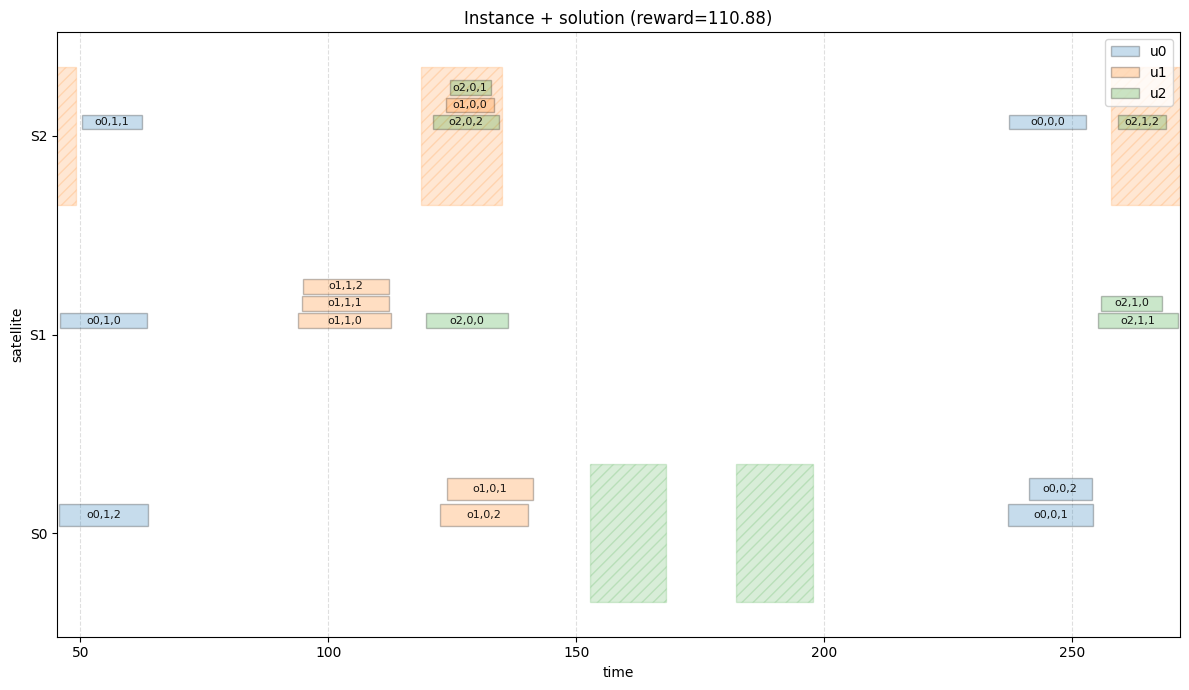

In [163]:
plot_eoscsp_windows(
P,
plan=None,
title=f"Instance + solution (reward={reward:.2f})",
show_exclusives=True,
show_labels=True,  
show_plan_labels=True
)

In [ ]:
plans_u, global_plan = s_dcop_EOSCSP_solver(P, tau=tau)

print("\n=== Final plans after s_dcop ===")
for o, st, en in global_plan:
    print(f"User u{o.u.u_id}:")
    print(f"  obs o{o.o_id} on S{o.s.s_id} [{st:.1f},{en:.1f}] r{o.r.r_id}")

plot_eoscsp_windows(
P,
plan=global_plan,
title=f"Instance + solution (reward={reward:.2f})",
show_exclusives=True,
show_labels=True,  
show_plan_labels=True
)

In [ ]:
print(format_eoscsp(P))

#### Instance article fin

In [123]:
# # ======================
# # Paramètres globaux
# # ======================
# horizon = 300.0

# NB_SAT = 3
# CAPACITY = 20

# NB_USERS_EXCL = 4
# NB_USERS_CENTRAL = 1   # le planner central

# # ======================
# # Satellites
# # ======================
# satellites = generate_satellites(
#     nb_satellites=NB_SAT,
#     horizon=horizon,
#     kappa_min=CAPACITY,
#     kappa_max=CAPACITY
# )

# # ======================
# # Utilisateur central (non exclusif)
# # ======================
# users_no_exclusifs = generate_users(
#     nb_users=NB_USERS_CENTRAL,
#     min_priority=1,
#     max_priority=1      # optionnel : même priorité
# )

# # ======================
# # Utilisateurs exclusifs
# # ======================
# users_exclusifs = generate_users_exclusifs(
#     k=len(users_no_exclusifs),
#     satellites=satellites,
#     nb_users=NB_USERS_EXCL,
#     k_excl_per_user=8,   # 8 exclusifs par user
#     e_dur_min=15,
#     e_dur_max=20
# )

# users = users_no_exclusifs.union(users_exclusifs)

# # ======================
# # Requêtes
# # ======================

# # --- requêtes des exclusifs : 2 à 20, reward discret [10,20,30,40,50]
# requests_excl = generate_requests(
#     users=users_exclusifs,
#     nb_requests_per_user=10,
#     horizon=horizon,
#     d_min=10.0,
#     d_max=20.0,
#     r_min=10.0,
#     r_max=50.0,
# )

# # --- requêtes du planner central : 8 à 80, reward [1..5]
# requests_central = generate_requests(
#     users=users_no_exclusifs,
#     nb_requests_per_user=50,
#     horizon=horizon,
#     d_min=10.0,
#     d_max=20.0,
#     r_min=1.0,
#     r_max=5.0,
# )

# requests = requests_excl.union(requests_central)

# # ======================
# # Observations
# # ======================
# observations = generate_observations(
#     satellites=satellites,
#     users=users,
#     requests=requests,
#     opp_per_request=10,     # 10 opportunités / requête
#     obs_window_min=10.0,
#     obs_window_max=20.0,
#     opp_duration=5.0        # durée fixe = 5
# )

# # ======================
# # Instance EOSCSP
# # ======================
# eoscsp_2 = generate_EOSCSP(
#     1,
#     satellites,
#     users,
#     requests,
#     observations
# )

# # ======================
# # Exemple : user 0 / satellite 0
# # ======================


In [125]:

# for algo in ["dsa", "mgm", "maxsum", "dpop"]:
#     print(f"\n=== Running s_dcop with {algo} ===")
#     plans_u, global_plan = s_dcop_EOSCSP_solver(eoscsp_2, tau=tau, algo=algo)
#     total = sum(o.reward for plan in plans_u.values() for (o,_,_) in plan)
#     print(f"Total reward with {algo}: {total:.2f}")
#     plot_eoscsp_windows(
#     P,
#     plan=global_plan,
#     title=f"Instance + solution (reward={reward:.2f})",
#     show_exclusives=True,
#     show_labels=True,  
#     show_plan_labels=True
#     )

In [126]:
#print(format_eoscsp(P))

#### Graphiques

In [77]:
N_RUNS = 5
HORIZON = 100.0

def make_pydcop_runner(algo_name):
    def _run(P, tau):
        print(f"  -> calling s_dcop_EOSCSP_solver(algo={algo_name})", flush=True)
        plans_u, global_plan = s_dcop_EOSCSP_solver(P, tau=tau, algo=algo_name)
        # reward total = somme des rewards des obs planifiées
        reward = sum(o.reward for (o, st, en) in global_plan)
        print(f"  -> done algo={algo_name}, nobs={len(global_plan)}, reward={reward:.1f}", flush=True)
        return global_plan, float(reward)
    return _run

PYDCOP_ALGOS = ["dsa", "mgm", "maxsum", "dpop"]

ALGOS = {
    "DCOP_dsa": make_pydcop_runner("dsa"),
    "DCOP_mgm": make_pydcop_runner("mgm"),
    "DCOP_maxsum": make_pydcop_runner("maxsum"),
    "DCOP_dpop": make_pydcop_runner("dpop"),
}

SIZES = {
    "small":  dict(n_sats=3, n_non_ex=1, n_ex=3, req_per_user=4, obs_per_req=5),
    "medium": dict(n_sats=5, n_non_ex=2, n_ex=5, req_per_user=6, obs_per_req=6),
    "large":  dict(n_sats=7, n_non_ex=3, n_ex=7, req_per_user=8, obs_per_req=7),
}

DIFFICULTIES = {
    "easy": dict(
        dur_min=4.0, dur_max=10.0,     # durées plus longues
        slack_min=14.0, slack_max=28.0,# fenêtres moins larges
        ex_windows=2,                  # plus d'exclusives
        tau_kind="mild"
    ),
    "medium": dict(
        dur_min=6.0, dur_max=16.0,
        slack_min=8.0, slack_max=18.0,
        ex_windows=3,
        tau_kind="hard"                # transitions plus pénalisantes
    ),
    "hard": dict(
        dur_min=10.0, dur_max=24.0,
        slack_min=5.0, slack_max=10.0, # fenêtres très étroites
        ex_windows=4,                  
        tau_kind="hard"
    ),
}

def tau_from_kind(kind):
    if kind == "hard":
        return lambda a, b: 2.0
    return lambda a, b: 1.0

def ideal_upper_bound(P):
    """
    Upper bound "théorique": somme_{r} max_{o in theta(r)} reward(o)
    Ignore contraintes -> borne sup.
    """
    best = {}
    for o in P.O:
        r = getattr(o, "r", None)
        if r is None:
            continue
        rew = float(getattr(o, "reward", getattr(o, "rho", 0.0)) or 0.0)
        best[r] = max(best.get(r, 0.0), rew)
    return float(sum(best.values())) if best else 0.0

def generate_instance(size_cfg, diff_cfg, horizon=HORIZON):
    # satellites
    satellites = generate_satellites(size_cfg["n_sats"], horizon, 100, 200)

    # users
    users_no_ex = generate_users(size_cfg["n_non_ex"])

    # NEW: on génère n_ex users exclusifs, avec ex_windows zones chacun
    users_ex = generate_users_exclusifs(
        k=len(users_no_ex),
        satellites=satellites,
        nb_users=size_cfg["n_ex"],
        k_excl_per_user=diff_cfg["ex_windows"],
        e_dur_min=15.0,   # à ajuster si tu veux que ça suive "difficulty"
        e_dur_max=20.0
    )

    users = users_no_ex.union(users_ex)

    # requests
    requests = generate_requests(
        users,
        size_cfg["req_per_user"],
        horizon,
        diff_cfg["dur_min"],
        diff_cfg["dur_max"],
        5.0,
        50.0,
    )

    # observations
    observations = generate_observations(
        satellites,
        users,
        requests,
        size_cfg["obs_per_req"],
        diff_cfg["slack_min"],
        diff_cfg["slack_max"],
    )

    P = generate_EOSCSP(0, satellites, users, requests, observations)
    return P


def run_one_algo(algo_fn, P, tau):
    t0 = time.perf_counter()
    plan, reward = algo_fn(P, tau=tau)
    t1 = time.perf_counter()
    return (t1 - t0), float(reward), plan

# ----------------------------
# RUN BENCH
# ----------------------------
# stockage brut : dict[size][difficulty][algo] -> list of metrics dict
raw = {size: {diff: {a: [] for a in ALGOS} for diff in DIFFICULTIES} for size in SIZES}

for size_name, size_cfg in SIZES.items():
    for diff_name, diff_cfg in DIFFICULTIES.items():
        tau = tau_from_kind(diff_cfg["tau_kind"])

        for run in range(N_RUNS):
            print(f"[GEN] size={size_name} diff={diff_name} run={run}", flush=True)
            P = generate_instance(size_cfg, diff_cfg, horizon=HORIZON)
            print(f"[OK ] generated |S|={len(P.S)} |U|={len(P.U)} |R|={len(P.R)} |O|={len(P.O)}", flush=True)

            ideal = ideal_upper_bound(P)
            if ideal <= 1e-12:
                ideal = 1e-12

            for algo_name, algo_fn in ALGOS.items():
                print(f"[SOL] {algo_name} size={size_name} diff={diff_name} run={run}", flush=True)
                runtime, reward, plan = run_one_algo(algo_fn, P, tau)
                print(f"[OK ] {algo_name} t={runtime:.3f}s reward={reward:.1f} nobs={len(plan)}", flush=True)

                reward_ratio = reward / ideal
                x_over_y = runtime / max(reward_ratio, 1e-9)  # runtime / reward_ratio

                raw[size_name][diff_name][algo_name].append({
                    "runtime": runtime,
                    "reward": reward,
                    "ideal": ideal,
                    "reward_ratio": reward_ratio,
                    "x_over_y": x_over_y,
                    "n_obs": len(plan),
                })

# ----------------------------
# AGG STATS (mean/std)
# ----------------------------
def mean_std(values):
    arr = np.array(values, dtype=float)
    if arr.size == 0:
        return 0.0, 0.0
    return float(arr.mean()), float(arr.std(ddof=1)) if arr.size > 1 else 0.0

# stats[size][diff][algo] -> dict metrics mean/std
stats = {size: {diff: {} for diff in DIFFICULTIES} for size in SIZES}

for size in SIZES:
    for diff in DIFFICULTIES:
        for algo in ALGOS:
            lst = raw[size][diff][algo]
            stats[size][diff][algo] = {
                "runtime_mean": mean_std([x["runtime"] for x in lst])[0],
                "runtime_std":  mean_std([x["runtime"] for x in lst])[1],
                "ratio_mean":   mean_std([x["reward_ratio"] for x in lst])[0],
                "ratio_std":    mean_std([x["reward_ratio"] for x in lst])[1],
                "x_over_y_mean":mean_std([x["x_over_y"] for x in lst])[0],
                "x_over_y_std": mean_std([x["x_over_y"] for x in lst])[1],
                "reward_mean":  mean_std([x["reward"] for x in lst])[0],
                "reward_std":   mean_std([x["reward"] for x in lst])[1],
                "nobs_mean":    mean_std([x["n_obs"] for x in lst])[0],
            }

# ----------------------------
# PRINT SUMMARY TABLE (text)
# ----------------------------
# for size in SIZES:
#     print("\n==============================")
#     print("SIZE:", size)
#     print("==============================")
#     for diff in DIFFICULTIES:
#         print(f"\n  Difficulty: {diff}")
#         for algo in ALGOS:
#             s = stats[size][diff][algo]
#             print(
#                 f"    {algo:10s} | "
#                 f"runtime={s['runtime_mean']:.4f}±{s['runtime_std']:.4f}s | "
#                 f"ratio={s['ratio_mean']:.3f}±{s['ratio_std']:.3f} | "
#                 f"x/y={s['x_over_y_mean']:.4f}±{s['x_over_y_std']:.4f} | "
#                 f"nobs~{s['nobs_mean']:.2f}"
#             )

def plot_all_sizes_grid():
    sizes = list(SIZES.keys())          # rows
    diffs = list(DIFFICULTIES.keys())
    algos = list(ALGOS.keys())

    fig, axes = plt.subplots(
        nrows=len(sizes),
        ncols=3,
        figsize=(18, 12),
        sharex=False
    )

    for row, size in enumerate(sizes):
        x = np.arange(len(diffs))
        width = 0.25
        offsets = np.linspace(-width, width, len(algos))

        # ------------------
        # 1) Runtime (log)
        # ------------------
        ax = axes[row, 0]
        for i, algo in enumerate(algos):
            means = [stats[size][d][algo]["runtime_mean"] for d in diffs]
            stds  = [stats[size][d][algo]["runtime_std"] for d in diffs]
            ax.bar(x + offsets[i], means, width=width, yerr=stds, capsize=3, label=algo)

        ax.set_yscale("log")
        ax.set_xticks(x)
        ax.set_xticklabels(diffs)
        ax.set_title(f"{size} – Runtime")
        ax.set_ylabel("runtime (s)")

        # ------------------
        # 2) Reward ratio
        # ------------------
        ax = axes[row, 1]
        for i, algo in enumerate(algos):
            means = [stats[size][d][algo]["ratio_mean"] for d in diffs]
            stds  = [stats[size][d][algo]["ratio_std"] for d in diffs]
            ax.bar(x + offsets[i], means, width=width, yerr=stds, capsize=3)

        ax.set_xticks(x)
        ax.set_xticklabels(diffs)
        ax.set_ylim(0, 1.05)
        ax.set_title(f"{size} – Reward / ideal")

        # ------------------
        # 3) Scatter runtime vs reward
        # ------------------
        ax = axes[row, 2]
        for algo in algos:
            xs, ys = [], []
            for diff in diffs:
                for rec in raw[size][diff][algo]:
                    xs.append(rec["runtime"])
                    ys.append(rec["reward_ratio"])
            ax.scatter(xs, ys, alpha=0.6, label=algo)

        ax.set_xscale("log")
        ax.set_title(f"{size} – Runtime vs reward")
        ax.set_xlabel("runtime (s)")
        ax.set_ylabel("reward ratio")

        # legend seulement sur la première ligne
        if row == 0:
            axes[row, 0].legend()
            axes[row, 2].legend()

    plt.tight_layout()
    plt.show()
    
plot_all_sizes_grid()    

[GEN] size=small diff=easy run=0


RuntimeError: Impossible de générer l'observation #1/5 pour r0 (fenêtre requête trop courte ou exclusives trop contraignantes).

## 4 - Partie 2 : Approches par enchères

### Utils:
- **solve_rest** une fois le plan partiel M_u0 fixé par l’enchère, on remplit gloutonnement avec des observations restantes.
- **bid** renvoie la meilleure observation de la requête r que u peut ajouter à son plan courant, en maximisant le reward sous contraintes de faisabilité.

In [263]:
def solve_central_with_fixed(P, M_fixed, U_ex, u0, tau):
    """solve(P[u0 | M_fixed]) : complète hors exclusives."""
    R = {s: [] for s in P.S}
    served = set()
    plan = list(M_fixed)

    for o, t, _ in M_fixed:
        R[o.s].append((o, float(t)))
        if getattr(o, "r", None) is not None:
            served.add(o.r)
    for s in R:
        R[s].sort(key=lambda x: x[1])

    candidates = [o for o in P.O if getattr(o, "r", None) not in served]
    candidates.sort(key=lambda o: (getattr(o, "p", 0), float(o.t_start)))

    for o in candidates:
        r = getattr(o, "r", None)
        if r is not None and r in served:
            continue

        t = first_slot(o, u0, R, tau)
        if t is None:
            continue
        end = t + float(o.duration)

        if overlaps_any_exclusive_interval(o.s, t, end, U_ex):

            R[o.s] = [(oo, tt) for (oo, tt) in R[o.s] if not (oo == o and abs(tt - t) < 1e-9)]
            continue

        plan.append((o, t, end))
        if r is not None:
            served.add(r)

    plan.sort(key=lambda x: x[1])
    return plan


def bid(P, r, u, M_u_plan, tau):
    """
    - reconstruit timeline depuis M_u
    - choisit l'observation de r de reward max insérable
    Retour: (best_gain, sigma=(o,t)) ou (-inf,None)
    """
    R = {s: [] for s in P.S}
    served = set()
    for obs, st, _ in M_u_plan:
        R[obs.s].append((obs, float(st)))
        if getattr(obs, "r", None) is not None:
            served.add(obs.r)
    for s in R:
        R[s].sort(key=lambda x: x[1])

    if r in served:
        return float("-inf"), None

    cand = [o for o in P.O if getattr(o, "r", None) == r]
    best_b = float("-inf")
    best_sigma = None

    for o in cand:

        ok = False
        for _ in domains_for(o, u):
            ok = True
            break
        if not ok:
            continue

        Rcopy = {s: list(R[s]) for s in R}
        t = first_slot(o, u, Rcopy, tau)
        if t is None:
            continue

        gain = float(getattr(o, "reward", getattr(o, "rho", 0.0)) or 0.0)
        if gain > best_b:
            best_b = gain
            best_sigma = (o, t)

    return best_b, best_sigma

### 4.1 - Enchères parallèles (PSI)

1. Chaque utilisateur exclusif calcule un plan local et des bids pour toutes les requêtes.
2. Pour chaque requête, le meilleur bid est sélectionné et inséré dans la timeline globale.
3. Une complétion centrale finalise le plan global.

In [264]:
def psi_solver(P, tau):

    U_ex = [u for u in P.U if is_exclusive(u)]
    u0 = next((u for u in P.U if not is_exclusive(u)), None)
    if u0 is None:
        u0 = type("CentralUser", (), {"e": []})()

    M_u0 = []

    # solve(P[u]) + bids "parallèles"
    M_u = {}
    bids = {}
    sigma = {}
    for u in U_ex:
        _, _, M_u[u] = greedy_solver(P, tau=tau, u=u, restrict_to_exclusives=True)
        for r in P.R:
            b, sig = bid(P, r, u, M_u[u], tau)
            bids[(u, r)] = b
            sigma[(u, r)] = sig


    R0 = {s: [] for s in P.S}
    served_global = set()

    for r in P.R:
        if r in served_global:
            continue

        w = None
        best_b = float("-inf")
        best_sig = None

        for u in U_ex:
            b = bids[(u, r)]
            sig = sigma[(u, r)]
            if sig is None:
                continue
            if b > best_b:
                best_b = b
                w = u
                best_sig = sig

        if w is None or best_sig is None or best_b == float("-inf"):
            continue

        o_win, _t_win = best_sig
        t = first_slot(o_win, w, R0, tau)
        if t is None:
            continue

        M_u0.append((o_win, t, t + float(o_win.duration)))
        served_global.add(r)


    M_u0 = solve_central_with_fixed(P, M_u0, U_ex, u0, tau)

    M_u0.sort(key=lambda x: x[1])
    return M_u0, plan_reward(M_u0)

### 4.2 - Enchères séquentielles (SSI)

1. Chaque utilisateur exclusif construit un plan local sur ses exclusives.
2. Les requêtes sont traitées séquentiellement : chaque user soumet un bid pour la requête courante.
3. Le meilleur bid gagne, et le plan du gagnant est mis à jour immédiatement.
4. Une complétion centrale finalise le plan global.

In [265]:
def ssi_solver(P, tau):

    U_ex = [u for u in P.U if is_exclusive(u)]
    u0 = next((u for u in P.U if not is_exclusive(u)), None)
    if u0 is None:
        u0 = type("CentralUser", (), {"e": []})()

    # Items auctionnés
    R_emit = [r for r in P.R if getattr(r, "u", None) == u0]

    # solve(P[u])
    M_u = {u: greedy_solver(P, tau=tau, u=u, restrict_to_exclusives=True)[2] for u in U_ex}

    # allocations gagnées
    M_u0 = []
    served_fixed = set()

    for r in sorted(R_emit, key=lambda rr: getattr(rr, "p", 0)):
        if r in served_fixed:
            continue

        best_u = None
        best_b = float("-inf")
        best_sigma = None

        for u in U_ex:
            b, sig = bid(P, r, u, M_u[u], tau)
            if sig is None:
                continue
            if b > best_b:
                best_b = b
                best_u = u
                best_sigma = sig

        if best_u is None or best_sigma is None or best_b == float("-inf"):
            continue

        o_win, t_win = best_sigma
        alloc = (o_win, t_win, t_win + float(o_win.duration))

        M_u0.append(alloc)
        served_fixed.add(r)


        M_u[best_u].append(alloc)
        M_u[best_u].sort(key=lambda x: x[1])

    final_plan = solve_central_with_fixed(P, M_u0, U_ex, u0, tau)
    final_plan.sort(key=lambda x: x[1])
    return final_plan, plan_reward(final_plan)

### 4.3 - Enchères séquentielles avec regret (SSI-Regret)

1. Chaque utilisateur exclusif construit un plan local sur ses exclusives.
2. À chaque tour, on calcule les bids et le regret pour chaque requête restante.
3. La requête de regret maximal est allouée, et le plan du gagnant est mis à jour.
4. Une complétion centrale finalise le plan global.

In [266]:
def ssi_regret_solver(P, tau, eps=1e-12):
    

    U_ex = [u for u in P.U if is_exclusive(u)]
    u0 = next((u for u in P.U if not is_exclusive(u)), None)
    if u0 is None:
        u0 = type("CentralUser", (), {"e": []})()

    # Requests auctionnés
    R_emit = [r for r in P.R if getattr(r, "u", None) == u0]
    remaining = list(R_emit)


    M_u = {
        u: greedy_solver(P, tau=tau, u=u, restrict_to_exclusives=True)[2]
        for u in U_ex
    }

    M_u0 = []

    # ---------- rounds ----------
    while remaining:

        best_info = {}   # r -> (best_gain, best_u, best_sigma=(o,t))
        second_best = {} # r -> second_best_gain (ou 0.0 si un seul bidder possible)

        any_feasible = False

        for r in remaining:
            per_u = []
            for u in U_ex:
                g, sig = bid(P, r, u, M_u[u], tau)   # bid SSI standard
                if sig is None or g == float("-inf"):
                    continue
                per_u.append((float(g), u, sig))

            if not per_u:
                best_info[r] = (float("-inf"), None, None)
                second_best[r] = float("-inf")
                continue

            any_feasible = True
            per_u.sort(key=lambda x: x[0], reverse=True)

            g1, u1, sig1 = per_u[0]
            g2 = per_u[1][0] if len(per_u) >= 2 else 0.0  # si seul bidder: second=0

            best_info[r] = (g1, u1, sig1)
            second_best[r] = g2

        if not any_feasible:
            break
        

        # choisir r* max regret
        r_star = None
        best_regret = float("-inf")
        best_g1 = float("-inf")

        for r in remaining:
            g1, u1, sig1 = best_info[r]
            if sig1 is None or g1 == float("-inf"):
                continue

            g2 = second_best[r]
            regret = g1 - g2


            if (regret > best_regret + eps) or (abs(regret - best_regret) <= eps and g1 > best_g1 + eps):
                best_regret = regret
                best_g1 = g1
                r_star = r

        if r_star is None:
            break


        g_win, u_win, (o_win, t_win) = best_info[r_star]
        alloc = (o_win, float(t_win), float(t_win) + float(o_win.duration))

        M_u0.append(alloc)
        M_u[u_win].append(alloc)
        M_u[u_win].sort(key=lambda x: x[1])

        remaining.remove(r_star)


    final_plan = solve_central_with_fixed(P, M_u0, U_ex, u0, tau)
    total_reward = plan_reward(final_plan)
    return final_plan, total_reward

### Graphiques: Runtime et Qualité

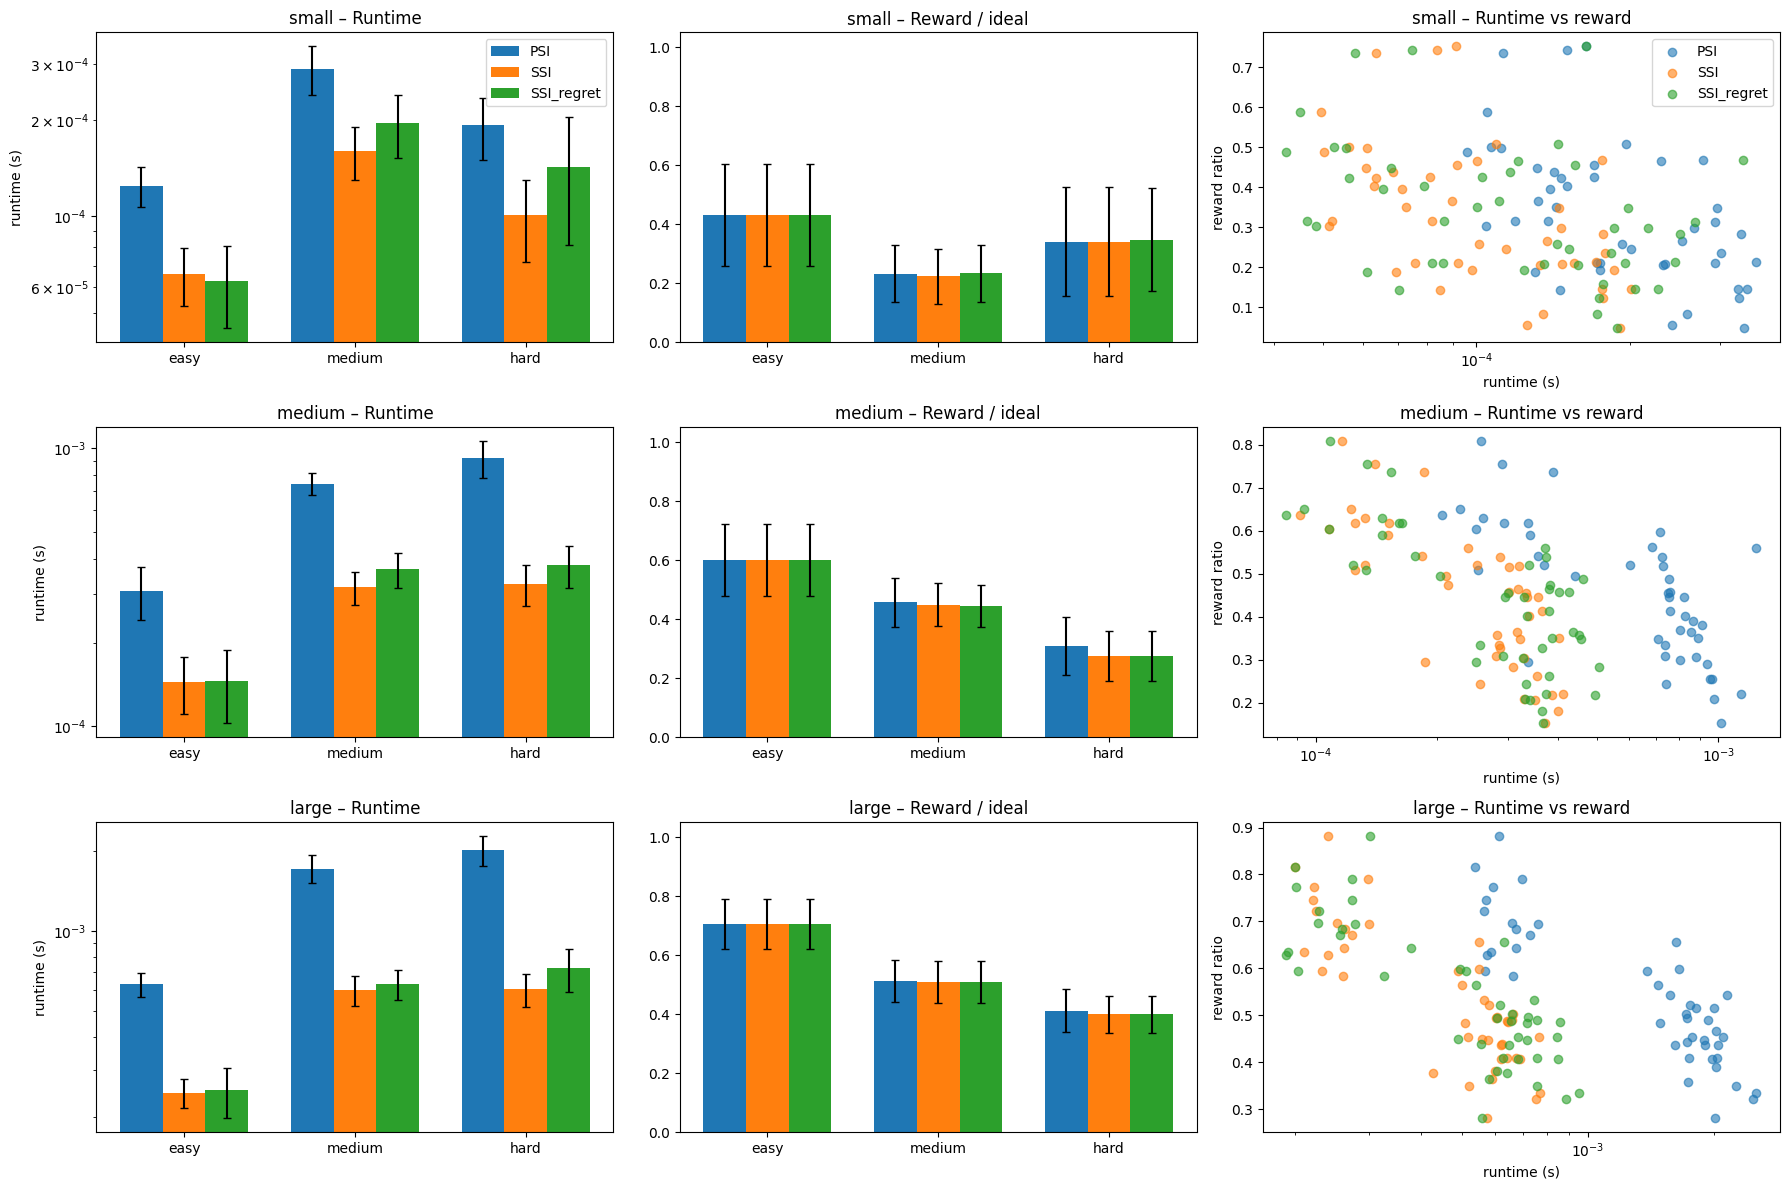

In [267]:
N_RUNS = 15
HORIZON = 100.0

ALGOS = {
    "PSI": psi_solver,
    "SSI": ssi_solver,
    "SSI_regret": ssi_regret_solver, 
}

SIZES = {
    "small":  dict(n_sats=3, n_non_ex=1, n_ex=3, req_per_user=4, obs_per_req=5),
    "medium": dict(n_sats=5, n_non_ex=2, n_ex=5, req_per_user=6, obs_per_req=6),
    "large":  dict(n_sats=7, n_non_ex=3, n_ex=7, req_per_user=8, obs_per_req=7),
}

DIFFICULTIES = {
    "easy": dict(
        dur_min=4.0, dur_max=10.0,     # durées plus longues
        slack_min=14.0, slack_max=28.0,# fenêtres moins larges
        ex_windows=2,                  # plus d'exclusives
        tau_kind="mild"
    ),
    "medium": dict(
        dur_min=6.0, dur_max=16.0,
        slack_min=8.0, slack_max=18.0,
        ex_windows=3,
        tau_kind="hard"                # transitions plus pénalisantes
    ),
    "hard": dict(
        dur_min=10.0, dur_max=24.0,
        slack_min=5.0, slack_max=10.0, # fenêtres très étroites
        ex_windows=4,                  
        tau_kind="hard"
    ),
}

def tau_from_kind(kind):
    if kind == "hard":
        return lambda a, b: 2.0
    return lambda a, b: 1.0

def ideal_upper_bound(P):
    """
    Upper bound "théorique": somme_{r} max_{o in theta(r)} reward(o)
    Ignore contraintes -> borne sup.
    """
    best = {}
    for o in P.O:
        r = getattr(o, "r", None)
        if r is None:
            continue
        rew = float(getattr(o, "reward", getattr(o, "rho", 0.0)) or 0.0)
        best[r] = max(best.get(r, 0.0), rew)
    return float(sum(best.values())) if best else 0.0

def generate_instance(size_cfg, diff_cfg, horizon=HORIZON):
    # satellites
    satellites = generate_satellites(size_cfg["n_sats"], horizon, 100, 200)

    # users
    users_no_ex = generate_users(size_cfg["n_non_ex"])
    users_ex = generate_users_exclusifs(len(users_no_ex), satellites, diff_cfg["ex_windows"])
    users = users_no_ex.union(users_ex)

    # requests
    requests = generate_requests(
        users,
        size_cfg["req_per_user"],
        horizon,
        diff_cfg["dur_min"],
        diff_cfg["dur_max"],
        5.0,
        50.0,
    )

    # observations
    observations = generate_observations(
        satellites,
        users,
        requests,
        size_cfg["obs_per_req"],
        diff_cfg["slack_min"],
        diff_cfg["slack_max"],
    )

    P = generate_EOSCSP(0, satellites, users, requests, observations)
    return P

def run_one_algo(algo_fn, P, tau):
    t0 = time.perf_counter()
    plan, reward = algo_fn(P, tau=tau)
    t1 = time.perf_counter()
    return (t1 - t0), float(reward), plan

# ----------------------------
# RUN BENCH
# ----------------------------
# stockage brut : dict[size][difficulty][algo] -> list of metrics dict
raw = {size: {diff: {a: [] for a in ALGOS} for diff in DIFFICULTIES} for size in SIZES}

for size_name, size_cfg in SIZES.items():
    for diff_name, diff_cfg in DIFFICULTIES.items():
        tau = tau_from_kind(diff_cfg["tau_kind"])

        for run in range(N_RUNS):
            P = generate_instance(size_cfg, diff_cfg, horizon=HORIZON)
            ideal = ideal_upper_bound(P)
            if ideal <= 1e-12:
                ideal = 1e-12

            for algo_name, algo_fn in ALGOS.items():
                runtime, reward, plan = run_one_algo(algo_fn, P, tau)

                reward_ratio = reward / ideal
                x_over_y = runtime / max(reward_ratio, 1e-9)  # runtime / reward_ratio

                raw[size_name][diff_name][algo_name].append({
                    "runtime": runtime,
                    "reward": reward,
                    "ideal": ideal,
                    "reward_ratio": reward_ratio,
                    "x_over_y": x_over_y,
                    "n_obs": len(plan),
                })

# ----------------------------
# AGG STATS (mean/std)
# ----------------------------
def mean_std(values):
    arr = np.array(values, dtype=float)
    if arr.size == 0:
        return 0.0, 0.0
    return float(arr.mean()), float(arr.std(ddof=1)) if arr.size > 1 else 0.0

# stats[size][diff][algo] -> dict metrics mean/std
stats = {size: {diff: {} for diff in DIFFICULTIES} for size in SIZES}

for size in SIZES:
    for diff in DIFFICULTIES:
        for algo in ALGOS:
            lst = raw[size][diff][algo]
            stats[size][diff][algo] = {
                "runtime_mean": mean_std([x["runtime"] for x in lst])[0],
                "runtime_std":  mean_std([x["runtime"] for x in lst])[1],
                "ratio_mean":   mean_std([x["reward_ratio"] for x in lst])[0],
                "ratio_std":    mean_std([x["reward_ratio"] for x in lst])[1],
                "x_over_y_mean":mean_std([x["x_over_y"] for x in lst])[0],
                "x_over_y_std": mean_std([x["x_over_y"] for x in lst])[1],
                "reward_mean":  mean_std([x["reward"] for x in lst])[0],
                "reward_std":   mean_std([x["reward"] for x in lst])[1],
                "nobs_mean":    mean_std([x["n_obs"] for x in lst])[0],
            }

# ----------------------------
# PRINT SUMMARY TABLE (text)
# ----------------------------
# for size in SIZES:
#     print("\n==============================")
#     print("SIZE:", size)
#     print("==============================")
#     for diff in DIFFICULTIES:
#         print(f"\n  Difficulty: {diff}")
#         for algo in ALGOS:
#             s = stats[size][diff][algo]
#             print(
#                 f"    {algo:10s} | "
#                 f"runtime={s['runtime_mean']:.4f}±{s['runtime_std']:.4f}s | "
#                 f"ratio={s['ratio_mean']:.3f}±{s['ratio_std']:.3f} | "
#                 f"x/y={s['x_over_y_mean']:.4f}±{s['x_over_y_std']:.4f} | "
#                 f"nobs~{s['nobs_mean']:.2f}"
#             )

def plot_all_sizes_grid():
    sizes = list(SIZES.keys())          # rows
    diffs = list(DIFFICULTIES.keys())
    algos = list(ALGOS.keys())

    fig, axes = plt.subplots(
        nrows=len(sizes),
        ncols=3,
        figsize=(18, 12),
        sharex=False
    )

    for row, size in enumerate(sizes):
        x = np.arange(len(diffs))
        width = 0.25
        offsets = np.linspace(-width, width, len(algos))

        # ------------------
        # 1) Runtime (log)
        # ------------------
        ax = axes[row, 0]
        for i, algo in enumerate(algos):
            means = [stats[size][d][algo]["runtime_mean"] for d in diffs]
            stds  = [stats[size][d][algo]["runtime_std"] for d in diffs]
            ax.bar(x + offsets[i], means, width=width, yerr=stds, capsize=3, label=algo)

        ax.set_yscale("log")
        ax.set_xticks(x)
        ax.set_xticklabels(diffs)
        ax.set_title(f"{size} – Runtime")
        ax.set_ylabel("runtime (s)")

        # ------------------
        # 2) Reward ratio
        # ------------------
        ax = axes[row, 1]
        for i, algo in enumerate(algos):
            means = [stats[size][d][algo]["ratio_mean"] for d in diffs]
            stds  = [stats[size][d][algo]["ratio_std"] for d in diffs]
            ax.bar(x + offsets[i], means, width=width, yerr=stds, capsize=3)

        ax.set_xticks(x)
        ax.set_xticklabels(diffs)
        ax.set_ylim(0, 1.05)
        ax.set_title(f"{size} – Reward / ideal")

        # ------------------
        # 3) Scatter runtime vs reward
        # ------------------
        ax = axes[row, 2]
        for algo in algos:
            xs, ys = [], []
            for diff in diffs:
                for rec in raw[size][diff][algo]:
                    xs.append(rec["runtime"])
                    ys.append(rec["reward_ratio"])
            ax.scatter(xs, ys, alpha=0.6, label=algo)

        ax.set_xscale("log")
        ax.set_title(f"{size} – Runtime vs reward")
        ax.set_xlabel("runtime (s)")
        ax.set_ylabel("reward ratio")

        # legend seulement sur la première ligne
        if row == 0:
            axes[row, 0].legend()
            axes[row, 2].legend()

    plt.tight_layout()
    plt.show()
plot_all_sizes_grid()    

Sur des instances easy, les trois méthodes (PSI, SSI, SSI-Regret) atteignent des performances quasi optimales, vu que les conflits sont rares.

Lorsque la difficulté augmente (medium), PSI surpasse systématiquement SSI et SSI-Regret en qualité de solution, grâce à une meilleure coordination globale, au prix d’un temps de calcul plus élevé.

Dans les cas hard, où la faisabilité devient dominante , l’écart de qualité se réduit fortement et SSI apparaît comme un bon compromis rapidité / performance.
Enfin, SSI-Regret n’apporte qu’un gain marginal par rapport à SSI standard sur l’ensemble des configurations testées.

## 5 - Conclusion

## Références

[1] Gauthier Picard.  
    **Auction-based and Distributed Optimization Approaches for Scheduling
    Observations in Satellite Constellations with Exclusive Orbit Portions**.  
    ONERA / Université de Toulouse, 2014.

[2] Sven Koenig, Xiaoming Zheng, Craig Tovey, Philip Kilby,  
    Vangelis Markakis, Richard Borie, Pinar Keskinocak.  
    **Agent Coordination with Regret Clearing**.  
    *Proceedings of the AAAI Conference on Artificial Intelligence (AAAI)*, 2008.  